# Apresentação do problema

O dataset utilizado para a análise é o [Online Retail Dataset - UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail).
Suas principais características são:
 - contém dados transacionais de 01/12/2010 a 09/12/2011
 - é de uma empresa de varejo do Reino Unido
 - contém 541.909 registros

Os principais campos são:

| Campo     | Descrição                                   |
|-----------|---------------------------------------------|
| InvoiceNo       | Identificador da nota/pedido. Códigos iniciados por C indicam cancelamentos.     |
| StockCode       | Código do produto                     |
| Description     | Descrição do produto.                 |
| Quantity        | Quantidade de itens na transação.     |
| InvoiceDate     | Data e hora da transação.             |
| UnitPrice       | Preço unitário em libra esterlina.    |
| CustomerID      | Identificador do cliente.             |
| Country         | País do cliente.                      |

O objetivo desta análise de dados é responder a pergunta “Quais clientes têm maior probabilidade de comprar novamente nos próximos 60 dias e como podemos usar essa informação para priorizar ações comerciais?”.
Além disso, temos as seguintes informações acessórias para obter:

- evolução de receita
- padrões de compra
- comportamento por país
- concentração de receita
- recorrência
- evoluções/cancelamentos
- oportunidades de segmentação

Para a resolução do problema, foram utilizadas as seguintes bibliotecas:

In [1]:
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore', category=FutureWarning)

## Parâmetros da análise

Os valores usados em mais de um lugar ficam reunidos aqui, com nome. Para testar outra janela de previsão ou outra semente, basta mudar esta célula.

In [2]:
ARQUIVO_DE_DADOS = 'Online Retail.xlsx'
PAIS_SEDE = 'United Kingdom'           # concentra a maior parte das vendas, por isso é separado nas comparações
JANELA_DE_PREVISAO_DIAS = 60
PROPORCAO_DE_TESTE = 0.2
SEMENTE = 42
LIMIAR_DO_COEFICIENTE = 0.1            # seleção de variáveis pela regressão logística
TOP_CLIENTES_PRIORITARIOS = 50

## Funções auxiliares

Os mesmos passos (contar pedidos por período, desenhar gráficos, treinar e avaliar um modelo) aparecem muitas vezes na análise. Cada um virou uma função com nome, para que as células seguintes mostrem **o que** está sendo analisado, e não repitam **como**.

In [3]:
# ---------- Gráficos ----------

def grafico_de_barras(dados, x, y, titulo, rotulo_x, rotulo_y, paleta='viridis', tamanho=(12, 7), girar_rotulos=False):
    plt.figure(figsize=tamanho)
    categoria = y if dados[y].dtype == object else x
    sns.barplot(x=x, y=y, data=dados, hue=categoria, palette=paleta, legend=False)
    plt.title(titulo)
    plt.xlabel(rotulo_x)
    plt.ylabel(rotulo_y)
    if girar_rotulos:
        plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


def grafico_de_linha_no_tempo(series, titulo, rotulo_y, tamanho=(15, 6)):
    """series: lista de dicionários com dados, x, y e, opcionalmente, rotulo e cor."""
    plt.figure(figsize=tamanho)
    for serie in series:
        sns.lineplot(x=serie['x'], y=serie['y'], data=serie['dados'], label=serie.get('rotulo'), color=serie.get('cor'))
    plt.title(titulo)
    plt.xlabel('Data')
    plt.ylabel(rotulo_y)
    plt.grid(True)
    plt.xticks(rotation=45)
    if len(series) > 1:
        plt.legend()
    plt.tight_layout()
    plt.show()


# ---------- Preparação dos dados ----------

def eh_cancelamento(transacoes):
    return transacoes['InvoiceNo'].astype(str).str.startswith('C')


def limites_de_outlier(serie, quantil_inferior=0.10, quantil_superior=0.90):
    """Regra do IQR com os percentis 10 e 90 no lugar dos quartis, para cortar apenas os valores muito extremos."""
    inferior, superior = serie.quantile(quantil_inferior), serie.quantile(quantil_superior)
    amplitude = superior - inferior
    return inferior - 1.5 * amplitude, superior + 1.5 * amplitude


def pedidos_por_mes(transacoes, nome_da_contagem):
    contagem = transacoes.groupby(transacoes['InvoiceDate'].dt.to_period('M'))['InvoiceNo'].nunique().reset_index()
    contagem['InvoiceDate'] = contagem['InvoiceDate'].astype(str)
    contagem.columns = ['Mês', nome_da_contagem]
    return contagem


def pedidos_por_dia(transacoes, nome_da_contagem):
    contagem = transacoes.groupby(transacoes['InvoiceDate'].dt.normalize())['InvoiceNo'].nunique().reset_index()
    contagem.columns = ['Data', nome_da_contagem]
    return contagem


def sem_pais_sede(tabela, coluna_do_pais):
    return tabela[tabela[coluna_do_pais] != PAIS_SEDE]


def top_itens(serie, quantidade, nome_do_valor):
    """Transforma uma série indexada pela descrição do item em tabela Descrição | valor."""
    tabela = serie.head(quantidade).reset_index()
    tabela.columns = ['Descrição', nome_do_valor]
    return tabela


# ---------- Modelagem ----------

def calcular_rfm(transacoes, data_de_referencia, sufixo=''):
    rfm = transacoes.groupby('CustomerID').agg(**{
        'Recency' + sufixo: ('InvoiceDate', lambda datas: (data_de_referencia - datas.max()).days),  # dias desde a última compra
        'Frequency' + sufixo: ('InvoiceNo', 'nunique'),                                             # pedidos únicos
        'Monetary' + sufixo: ('Revenue', 'sum'),                                                    # receita total
    }).reset_index()
    return rfm.rename(columns={'CustomerID': 'ID'})


def dividir_treino_e_teste(X, y):
    return train_test_split(X, y, test_size=PROPORCAO_DE_TESTE, random_state=SEMENTE, stratify=y)


def regressao_logistica():
    return LogisticRegression(solver='liblinear', random_state=SEMENTE, class_weight='balanced', max_iter=1000)


def floresta_aleatoria():
    return RandomForestClassifier(n_estimators=100, random_state=SEMENTE, class_weight='balanced')


def arvore_de_decisao():
    return DecisionTreeClassifier(random_state=SEMENTE, class_weight='balanced')


def lightgbm():
    return lgb.LGBMClassifier(objective='binary', random_state=SEMENTE, is_unbalance=True, verbose=-1)


def xgboost_balanceado(y_treino):
    proporcao_negativos = (y_treino == 0).sum() / (y_treino == 1).sum()
    return xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', random_state=SEMENTE,
                             scale_pos_weight=proporcao_negativos)


def desenhar_curva_roc(modelo, X_teste, y_teste, nome, auc, cor):
    fig, ax = plt.subplots(figsize=(8, 6))
    RocCurveDisplay.from_estimator(modelo, X_teste, y_teste, ax=ax, name=f'{nome} (AUC = {auc:.2f})', color=cor)
    ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='Classificador Aleatório')
    ax.set_title(f'Curva ROC ({nome})')
    ax.legend(loc='lower right')
    ax.grid(True)
    plt.show()


def desenhar_matriz_de_confusao(y_teste, previsto, classes, nome, mapa_de_cores):
    ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_teste, previsto), display_labels=classes).plot(cmap=mapa_de_cores)
    plt.title(f'Matriz de Confusão ({nome})')
    plt.show()


def treinar_e_avaliar(modelo, nome, divisao, cor='blue', mapa_de_cores=plt.cm.Blues):
    """Treina o modelo, mostra relatório, curva ROC e matriz de confusão e devolve as métricas do teste."""
    X_treino, X_teste, y_treino, y_teste = divisao
    modelo.fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)
    probabilidade = modelo.predict_proba(X_teste)[:, 1]

    print(f'Relatório de Classificação ({nome}):')
    print(classification_report(y_teste, previsto))
    metricas = {
        'Acurácia': accuracy_score(y_teste, previsto),
        'Precisão (Classe 1)': precision_score(y_teste, previsto, pos_label=1),
        'Recall (Classe 1)': recall_score(y_teste, previsto, pos_label=1),
        'F1-Score (Classe 1)': f1_score(y_teste, previsto, pos_label=1),
        'ROC AUC Score': roc_auc_score(y_teste, probabilidade),
    }
    for metrica, valor in metricas.items():
        print(f'{metrica}: {valor:.4f}')

    desenhar_curva_roc(modelo, X_teste, y_teste, nome, metricas['ROC AUC Score'], cor)
    desenhar_matriz_de_confusao(y_teste, previsto, modelo.classes_, nome, mapa_de_cores)
    return metricas


def importancia_das_variaveis(modelo, nomes_das_variaveis, titulo, paleta='viridis'):
    """Usa os coeficientes (modelos lineares) ou a importância (árvores) e ordena pelo impacto absoluto."""
    if hasattr(modelo, 'coef_'):
        coluna, valores = 'Coeficiente', modelo.coef_[0]
    else:
        coluna, valores = 'Importância', modelo.feature_importances_
    tabela = pd.DataFrame({'Variável': nomes_das_variaveis, coluna: valores})
    tabela = tabela.reindex(tabela[coluna].abs().sort_values(ascending=False).index)
    display(tabela)
    grafico_de_barras(tabela, x=coluna, y='Variável', titulo=titulo, rotulo_x=coluna, rotulo_y='Variável',
                      paleta=paleta, tamanho=(12, max(4, 0.3 * len(tabela))))
    return tabela


def priorizar_clientes(modelo, X, base_de_clientes, coluna_da_probabilidade):
    priorizados = base_de_clientes.copy()
    priorizados[coluna_da_probabilidade] = modelo.predict_proba(X)[:, 1]
    return priorizados.sort_values(by=coluna_da_probabilidade, ascending=False)


def comparar_modelos(resultados):
    """resultados: dicionário {nome do modelo: métricas}. Mostra a tabela e o melhor modelo pelo F1 da classe 1."""
    tabela = pd.DataFrame(resultados)
    tabela.index.name = 'Métrica'
    display(tabela.T.round(4))
    f1 = tabela.loc['F1-Score (Classe 1)']
    print(f'O melhor modelo com base no F1-Score da classe 1 é: {f1.idxmax()} com F1-Score: {f1.max():.4f}')
    return tabela

# Extração dos dados

In [4]:
transacoes = pd.read_excel(ARQUIVO_DE_DADOS)
transacoes.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


# Limpeza dos dados

In [5]:
# Valores nulos por coluna
transacoes.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
# Linhas sem CustomerID não podem ser associadas a um cliente
transacoes = transacoes.dropna(subset=['CustomerID'])

# Os cancelamentos ficam separados para uma análise própria
cancelados = transacoes[eh_cancelamento(transacoes)].copy()
vendas = transacoes[~eh_cancelamento(transacoes)]

# Quantidades e preços precisam ser positivos
vendas = vendas[(vendas['Quantity'] > 0) & (vendas['UnitPrice'] > 0)]
cancelados

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315.0,United Kingdom


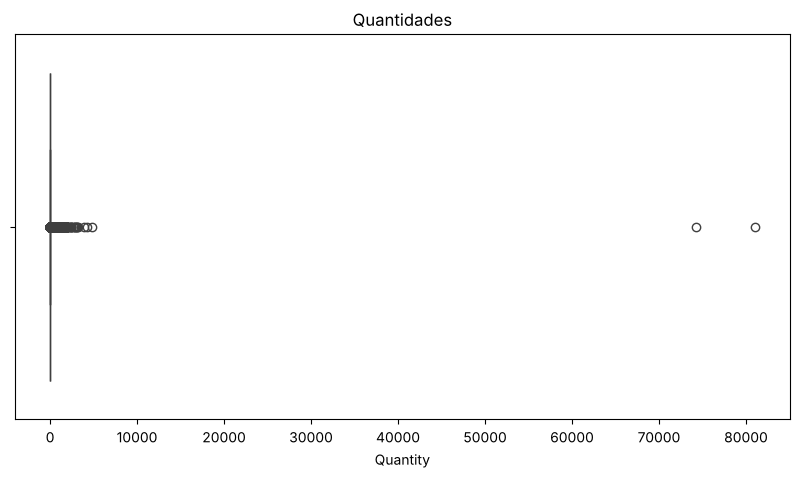

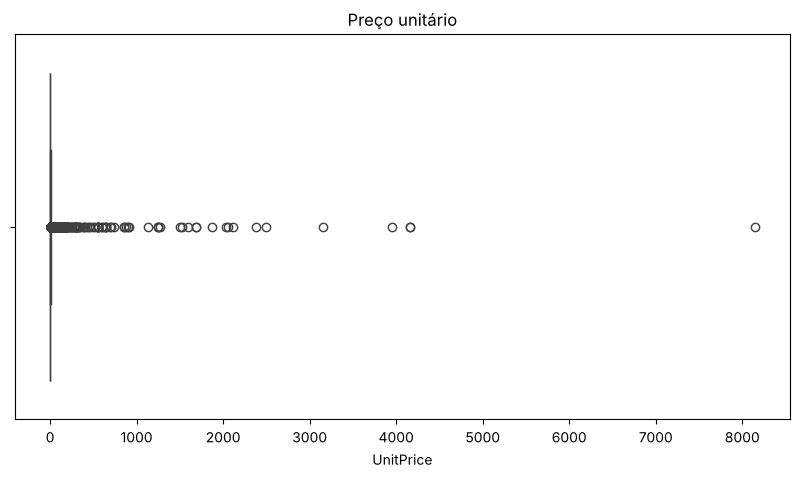

In [7]:
for coluna, titulo in [('Quantity', 'Quantidades'), ('UnitPrice', 'Preço unitário')]:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=vendas[coluna])
    plt.title(titulo)
    plt.xlabel(coluna)
    plt.show()

In [8]:
_, limite_da_quantidade = limites_de_outlier(vendas['Quantity'])
_, limite_do_preco = limites_de_outlier(vendas['UnitPrice'])
print(f"Limite superior de outlier para quantidade: {limite_da_quantidade}")
print(f"Limite superior de outlier para preço unitário: {limite_do_preco}")

vendas = vendas[(vendas['Quantity'] <= limite_da_quantidade) & (vendas['UnitPrice'] <= limite_do_preco)].copy()
vendas['Revenue'] = vendas['Quantity'] * vendas['UnitPrice']
print(f"Base após remoção de outliers: {vendas.shape[0]} linhas")
vendas.info()

Limite superior de outlier para quantidade: 58.5
Limite superior de outlier para preço unitário: 15.049999999999999
Base após remoção de outliers: 382861 linhas
<class 'pandas.core.frame.DataFrame'>
Index: 382861 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    382861 non-null  object        
 1   StockCode    382861 non-null  object        
 2   Description  382861 non-null  object        
 3   Quantity     382861 non-null  int64         
 4   InvoiceDate  382861 non-null  datetime64[ns]
 5   UnitPrice    382861 non-null  float64       
 6   CustomerID   382861 non-null  float64       
 7   Country      382861 non-null  object        
 8   Revenue      382861 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 29.2+ MB


# Análise Exploratória

## Informações gerais do negócio

In [9]:
numero_de_pedidos = vendas['InvoiceNo'].nunique()
numero_de_clientes = vendas['CustomerID'].nunique()
pedidos_por_cliente = vendas.groupby('CustomerID')['InvoiceNo'].nunique()

print(f"Número de pedidos não cancelados: {numero_de_pedidos}")
print(f"Número de clientes: {numero_de_clientes}")
print(f"Ticket médio: £ {vendas['Revenue'].sum() / numero_de_pedidos:.2f}")
print(f"Itens por pedido: {vendas['Quantity'].sum() / numero_de_pedidos:,.2f}")
print(f"Frequência de compra (pedidos por cliente): {numero_de_pedidos / numero_de_clientes:,.2f}")
print(f"Taxa de recorrência (clientes com mais de um pedido): {(pedidos_por_cliente > 1).mean() * 100:,.2f}%")

Número de pedidos não cancelados: 17626
Número de clientes: 4257
Ticket médio: £ 338.77
Itens por pedido: 181.39
Frequência de compra (pedidos por cliente): 4.14
Taxa de recorrência (clientes com mais de um pedido): 65.09%


,Mês,Nº Pedidos
11,2011-11,2547
10,2011-10,1830
9,2011-09,1674
5,2011-05,1473
0,2010-12,1334
6,2011-06,1328
7,2011-07,1267
3,2011-03,1254
8,2011-08,1206
4,2011-04,1077


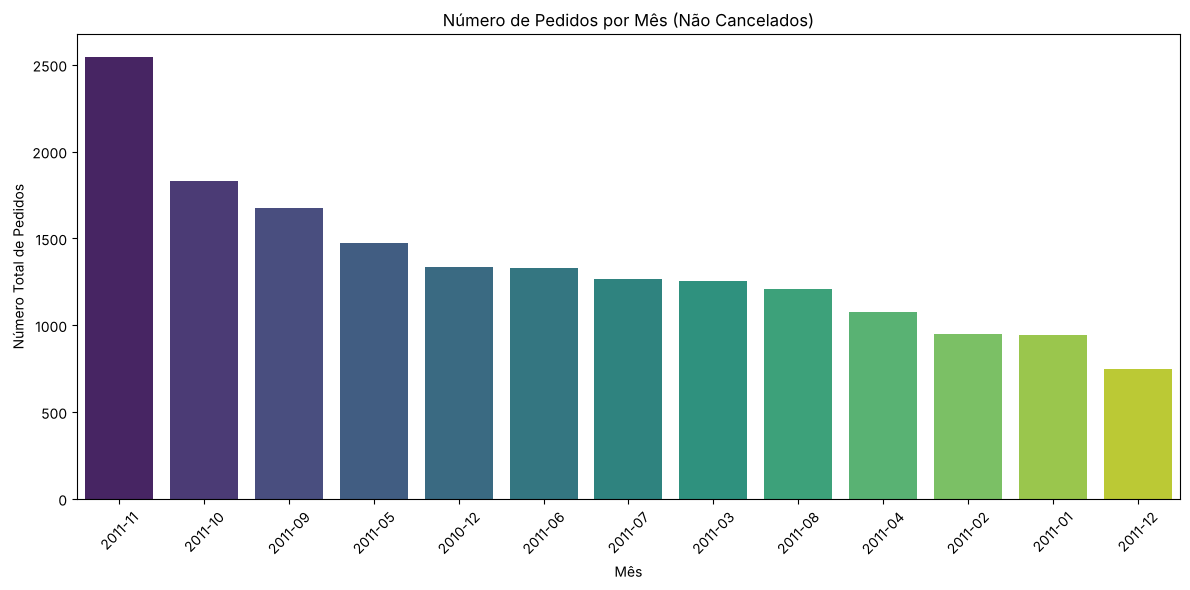

In [10]:
pedidos_mensais = pedidos_por_mes(vendas, 'Nº Pedidos')
pedidos_mensais_ordenados = pedidos_mensais.sort_values(by='Nº Pedidos', ascending=False)
display(pedidos_mensais_ordenados)
grafico_de_barras(pedidos_mensais_ordenados, x='Mês', y='Nº Pedidos', titulo='Número de Pedidos por Mês (Não Cancelados)',
                  rotulo_x='Mês', rotulo_y='Número Total de Pedidos', tamanho=(12, 6), girar_rotulos=True)

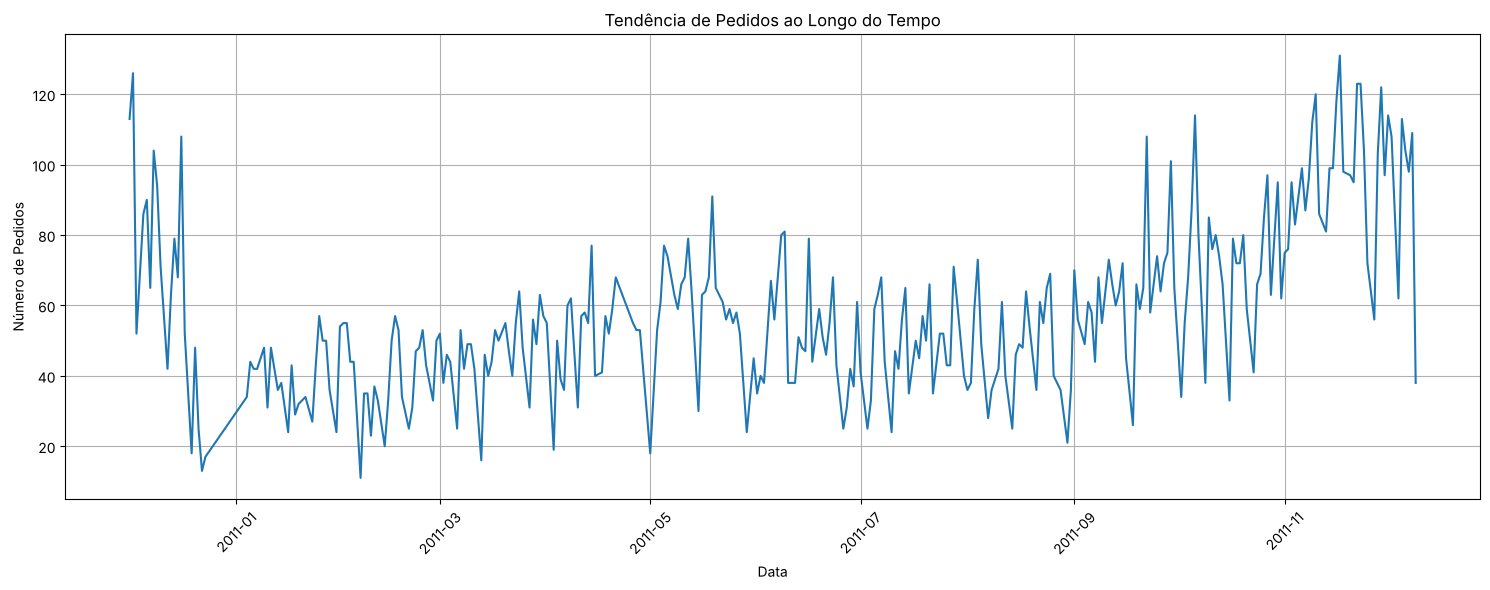

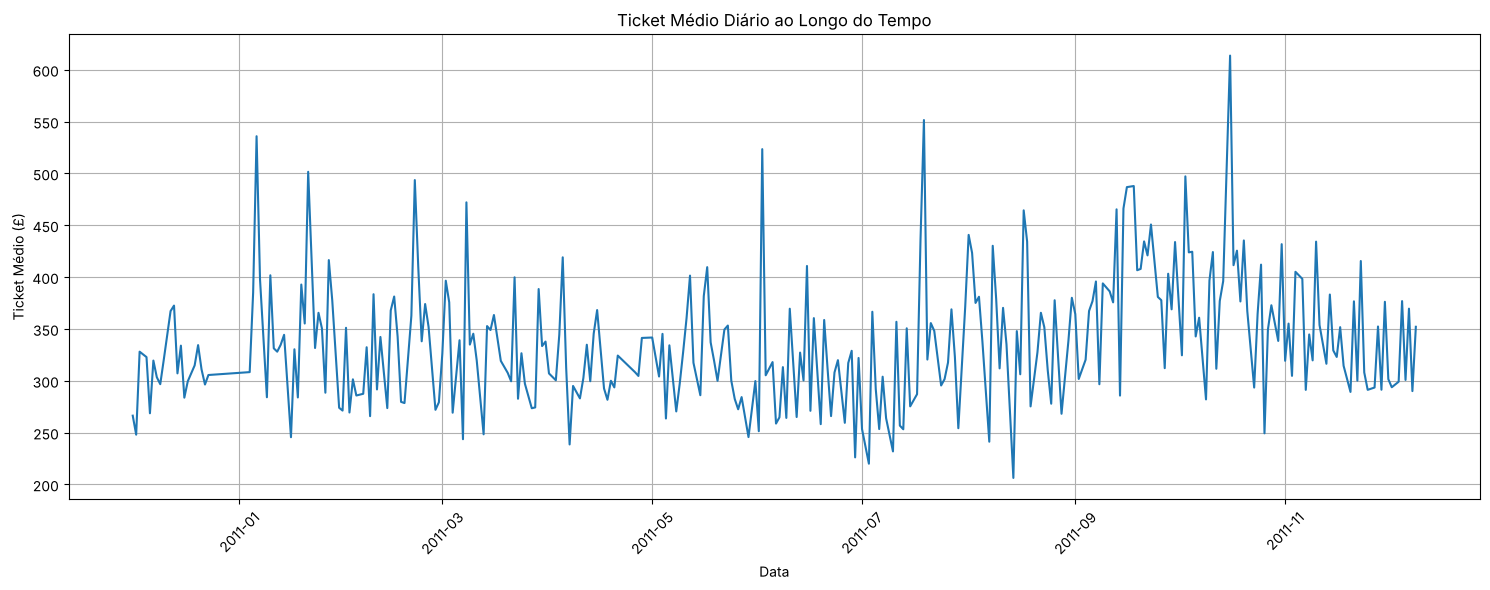

In [11]:
pedidos_diarios = pedidos_por_dia(vendas, 'Pedidos')
receita_diaria = vendas.groupby(vendas['InvoiceDate'].dt.normalize())['Revenue'].sum().reset_index(name='Receita')
ticket_diario = pedidos_diarios.merge(receita_diaria.rename(columns={'InvoiceDate': 'Data'}), on='Data')
ticket_diario['Ticket Médio'] = ticket_diario['Receita'] / ticket_diario['Pedidos']

grafico_de_linha_no_tempo([{'dados': pedidos_diarios, 'x': 'Data', 'y': 'Pedidos'}],
                          'Tendência de Pedidos ao Longo do Tempo', 'Número de Pedidos')
grafico_de_linha_no_tempo([{'dados': ticket_diario, 'x': 'Data', 'y': 'Ticket Médio'}],
                          'Ticket Médio Diário ao Longo do Tempo', 'Ticket Médio (£)')

Top 10 países por receita de vendas (excluindo Reino Unido):


,Country,Revenue
0,Germany,184288.57
1,EIRE,165157.10
2,France,157013.74
3,Netherlands,63226.12
4,Switzerland,45164.21
5,Spain,41402.84
6,Belgium,38035.84
7,Australia,36307.99
8,Norway,27913.17
9,Portugal,25813.88


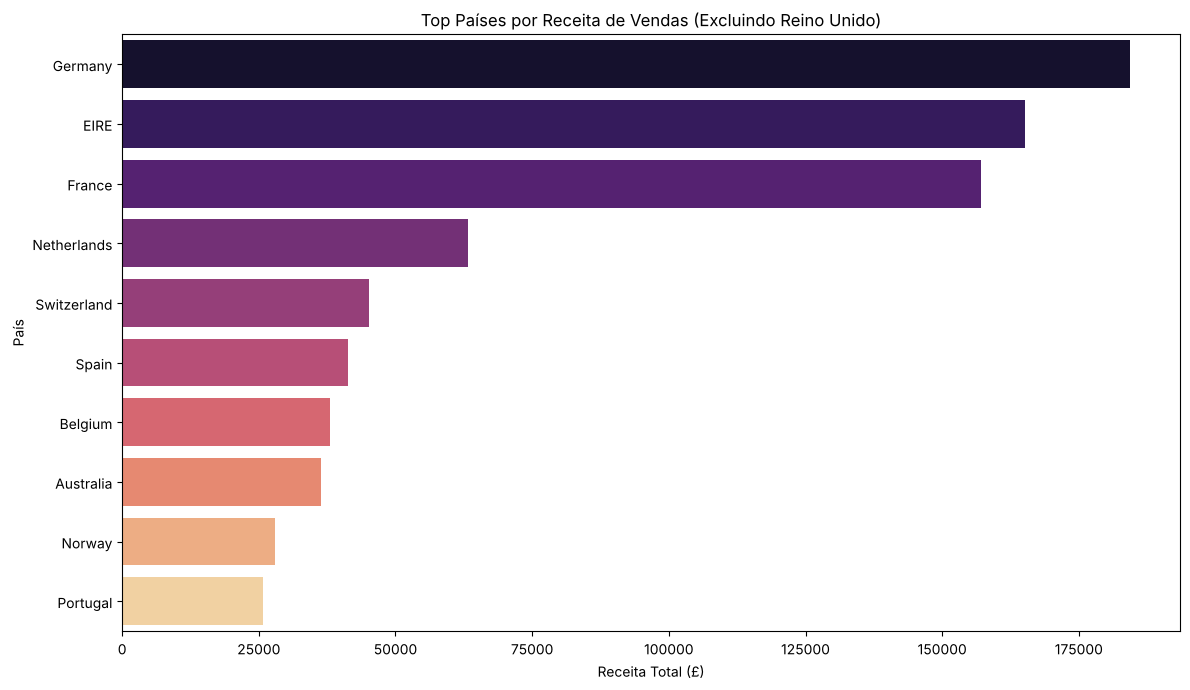

In [12]:
receita_por_pais = vendas.groupby('Country')['Revenue'].sum().reset_index()
top_paises_por_receita = sem_pais_sede(receita_por_pais, 'Country').sort_values(by='Revenue', ascending=False).head(10)

print("Top 10 países por receita de vendas (excluindo Reino Unido):")
display(top_paises_por_receita.reset_index(drop=True))
grafico_de_barras(top_paises_por_receita, x='Revenue', y='Country', titulo='Top Países por Receita de Vendas (Excluindo Reino Unido)',
                  rotulo_x='Receita Total (£)', rotulo_y='País', paleta='magma')

## Cancelamentos

In [13]:
numero_de_cancelamentos = len(cancelados)
total_de_pedidos = numero_de_pedidos + numero_de_cancelamentos

print(f"Número total de pedidos não cancelados: {numero_de_pedidos:,}")
print(f"Número total de pedidos cancelados: {numero_de_cancelamentos:,}")
print(f"Número total de todos os pedidos: {total_de_pedidos:,}")
print(f"Taxa de Cancelamento Geral: {numero_de_cancelamentos / total_de_pedidos * 100:,.2f}%")

Número total de pedidos não cancelados: 17,626
Número total de pedidos cancelados: 8,905
Número total de todos os pedidos: 26,531
Taxa de Cancelamento Geral: 33.56%


In [14]:
cancelamentos_mensais = pedidos_por_mes(cancelados, 'Cancelamentos')
display(cancelamentos_mensais.sort_values(by='Cancelamentos', ascending=False))

cancelamentos_diarios = pedidos_por_dia(cancelados, 'Qnt Cancelados')
print("10 dias com mais cancelamentos:")
display(cancelamentos_diarios.sort_values(by='Qnt Cancelados', ascending=False).head(10))

,Mês,Cancelamentos
11,2011-11,428
10,2011-10,334
9,2011-09,322
6,2011-06,314
0,2010-12,308
3,2011-03,298
5,2011-05,294
8,2011-08,263
7,2011-07,262
1,2011-01,249


10 dias com mais cancelamentos:


,Data,Qnt Cancelados
246,2011-10-06,64
11,2010-12-14,50
294,2011-12-01,46
51,2011-02-11,44
283,2011-11-18,39
271,2011-11-04,38
215,2011-08-31,38
276,2011-11-10,36
293,2011-11-30,35
71,2011-03-07,34


,Data,Pedidos,Qnt Cancelados,Taxa (%)
0,2010-12-01,113,6,5.309735
1,2010-12-02,126,23,18.253968
2,2010-12-03,52,7,13.461538
3,2010-12-05,86,7,8.139535
4,2010-12-06,90,17,18.888889


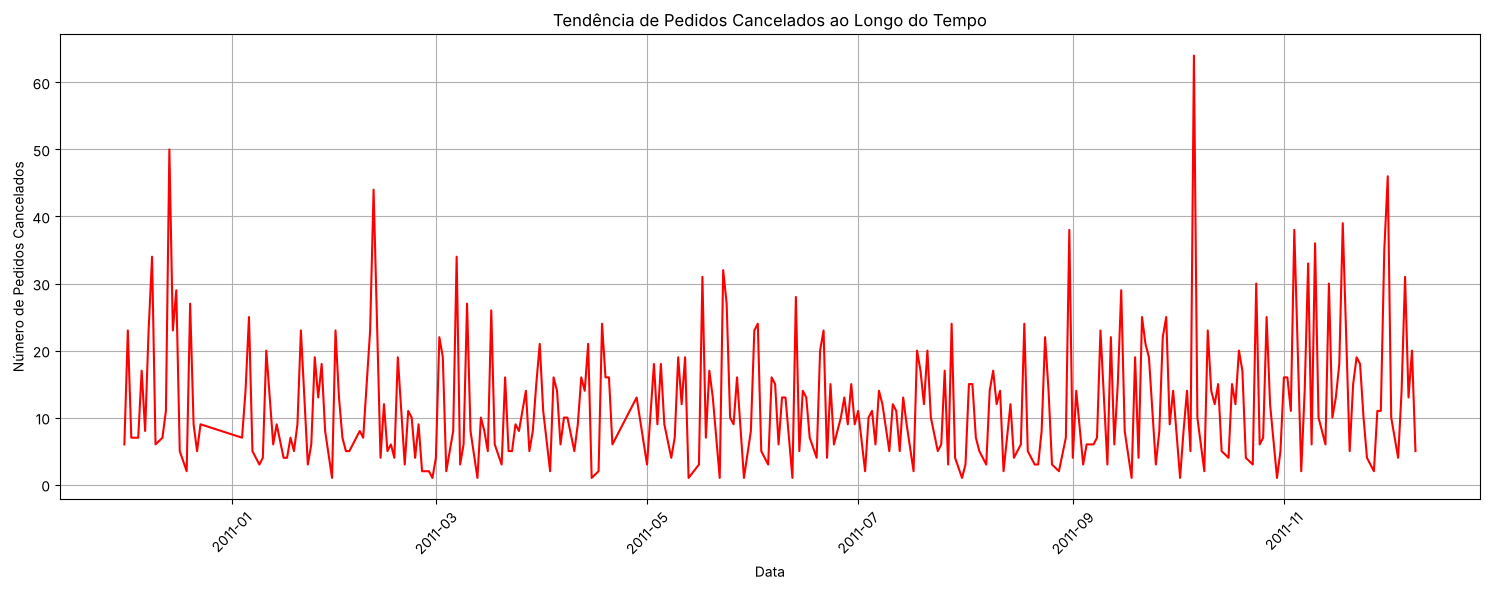

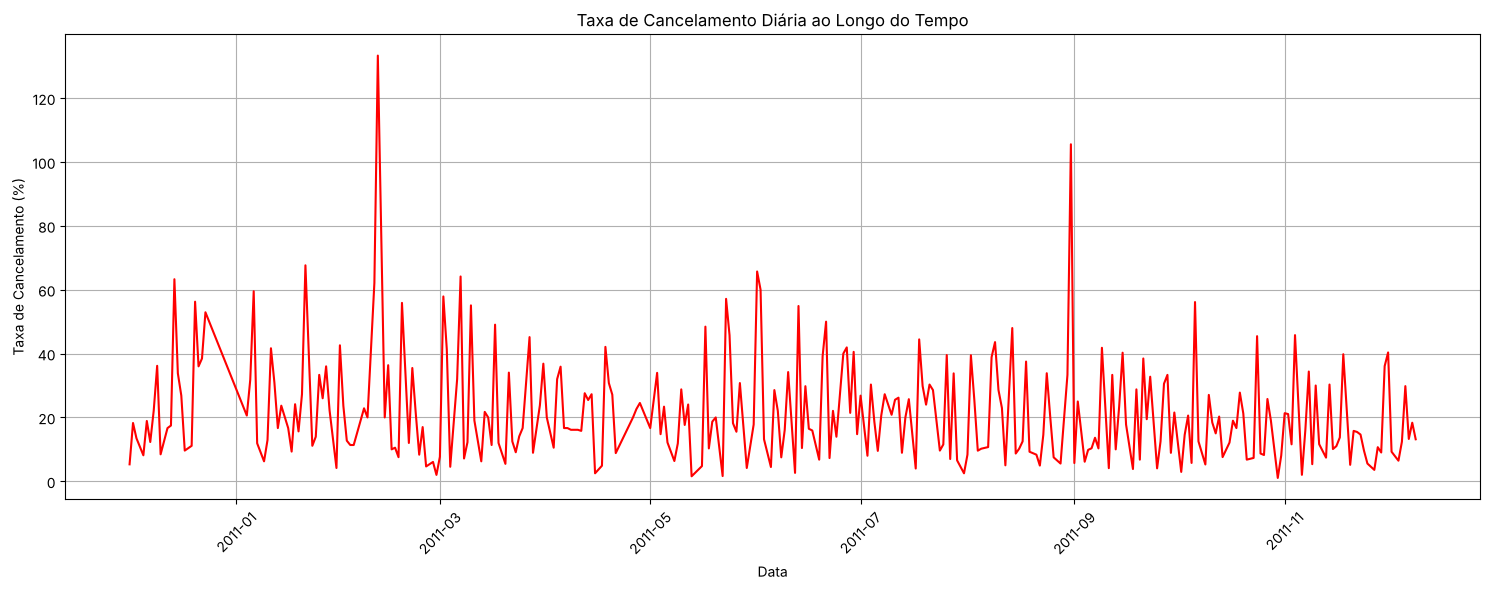

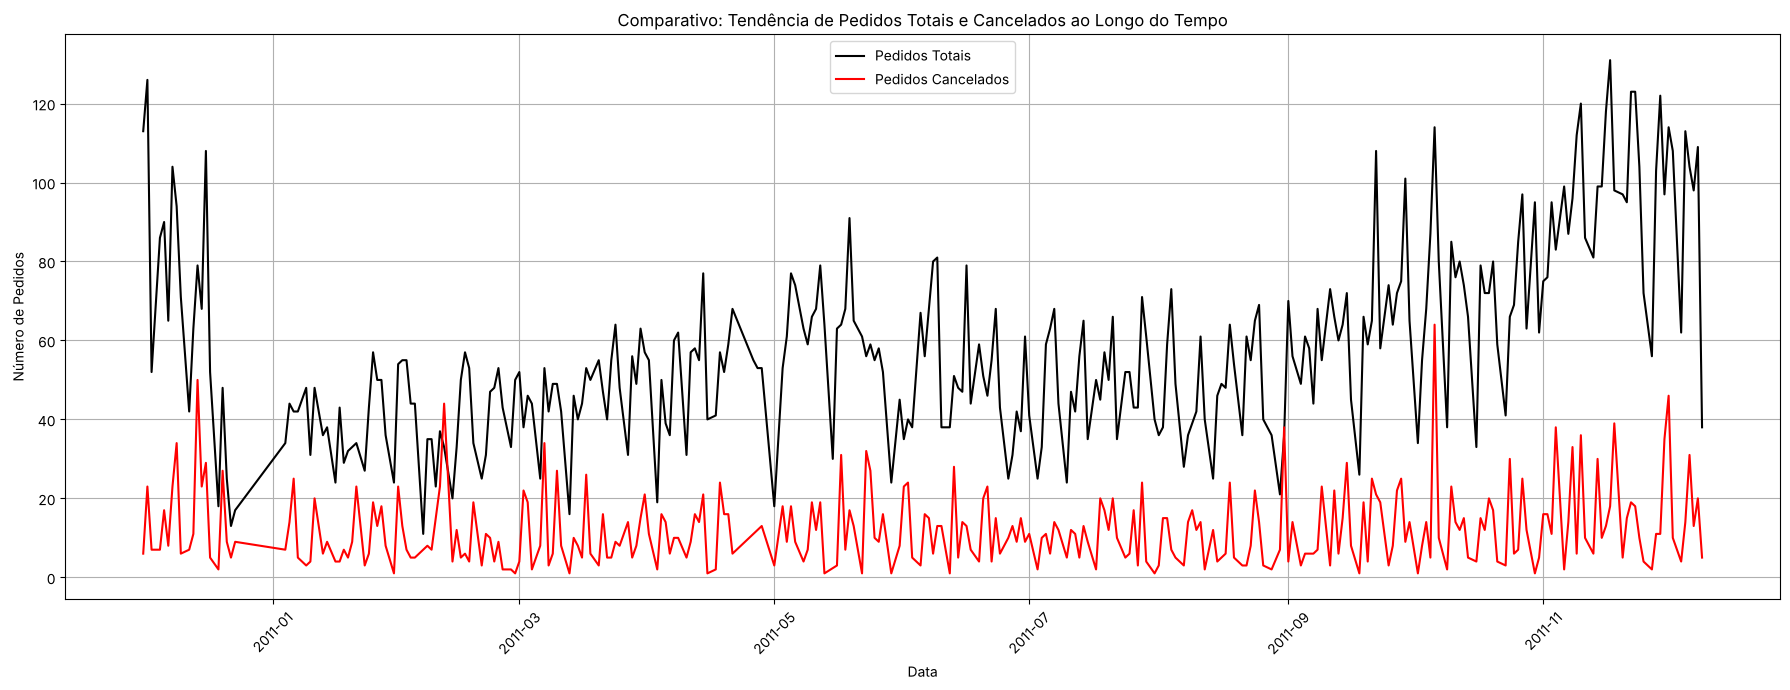

In [15]:
taxa_diaria = pedidos_diarios.merge(cancelamentos_diarios, on='Data')
taxa_diaria['Taxa (%)'] = taxa_diaria['Qnt Cancelados'] / taxa_diaria['Pedidos'] * 100
display(taxa_diaria.head())

grafico_de_linha_no_tempo([{'dados': cancelamentos_diarios, 'x': 'Data', 'y': 'Qnt Cancelados', 'cor': 'red'}],
                          'Tendência de Pedidos Cancelados ao Longo do Tempo', 'Número de Pedidos Cancelados')
grafico_de_linha_no_tempo([{'dados': taxa_diaria, 'x': 'Data', 'y': 'Taxa (%)', 'cor': 'red'}],
                          'Taxa de Cancelamento Diária ao Longo do Tempo', 'Taxa de Cancelamento (%)')
grafico_de_linha_no_tempo([{'dados': pedidos_diarios, 'x': 'Data', 'y': 'Pedidos', 'rotulo': 'Pedidos Totais', 'cor': 'black'},
                           {'dados': cancelamentos_diarios, 'x': 'Data', 'y': 'Qnt Cancelados', 'rotulo': 'Pedidos Cancelados', 'cor': 'red'}],
                          'Comparativo: Tendência de Pedidos Totais e Cancelados ao Longo do Tempo', 'Número de Pedidos', tamanho=(18, 7))

,Mês,Nº Pedidos,Cancelamentos
0,2010-12,1334,308
1,2011-01,941,249
2,2011-02,949,204
3,2011-03,1254,298
4,2011-04,1077,235
5,2011-05,1473,294
6,2011-06,1328,314
7,2011-07,1267,262
8,2011-08,1206,263
9,2011-09,1674,322


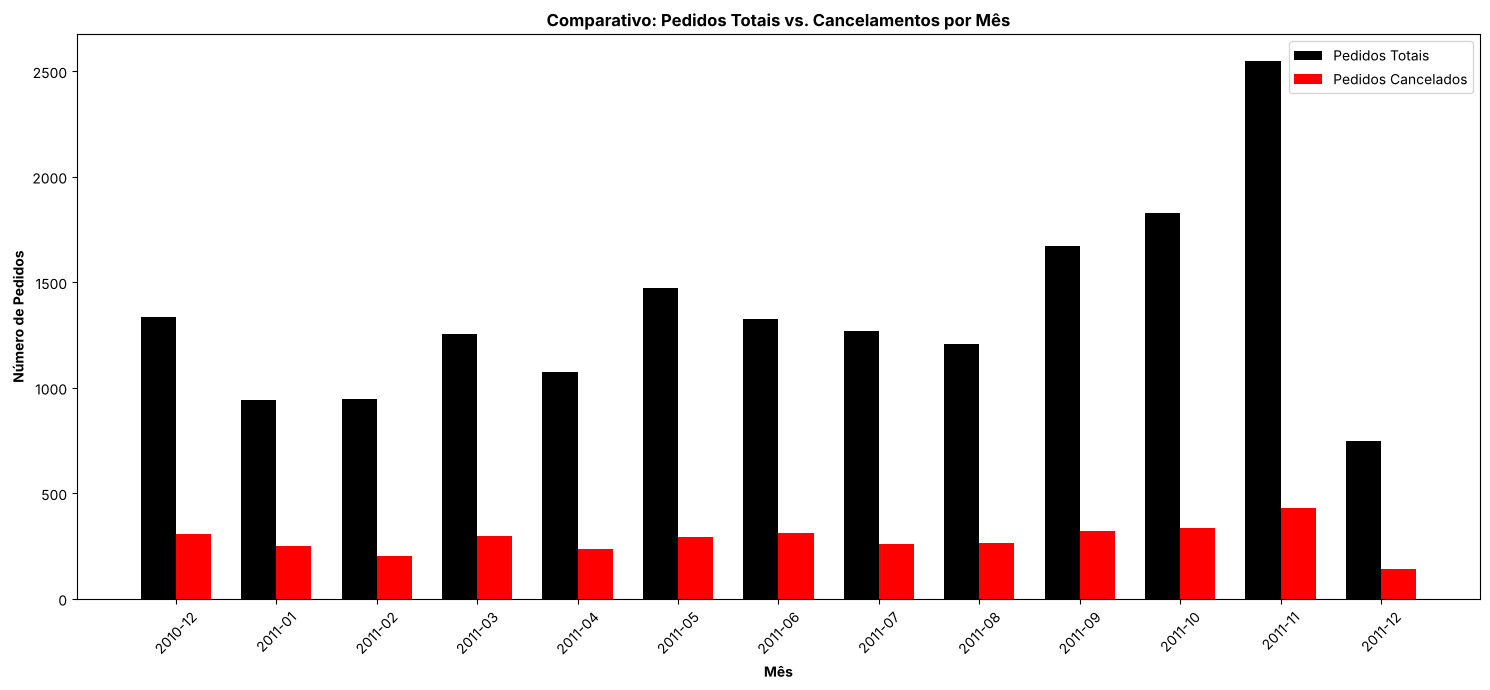

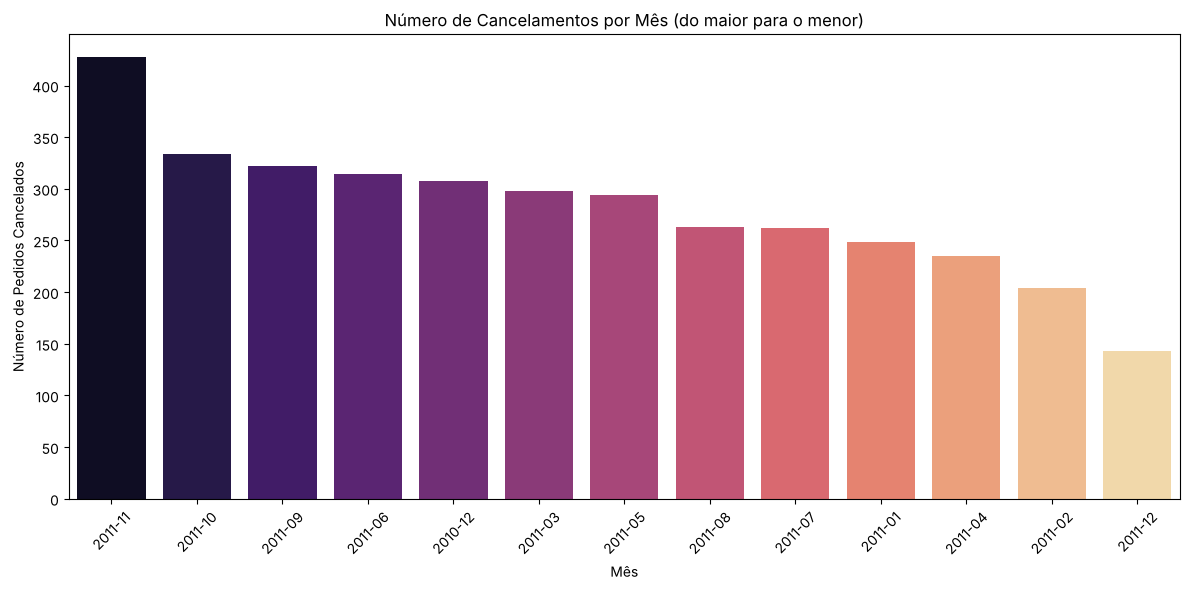

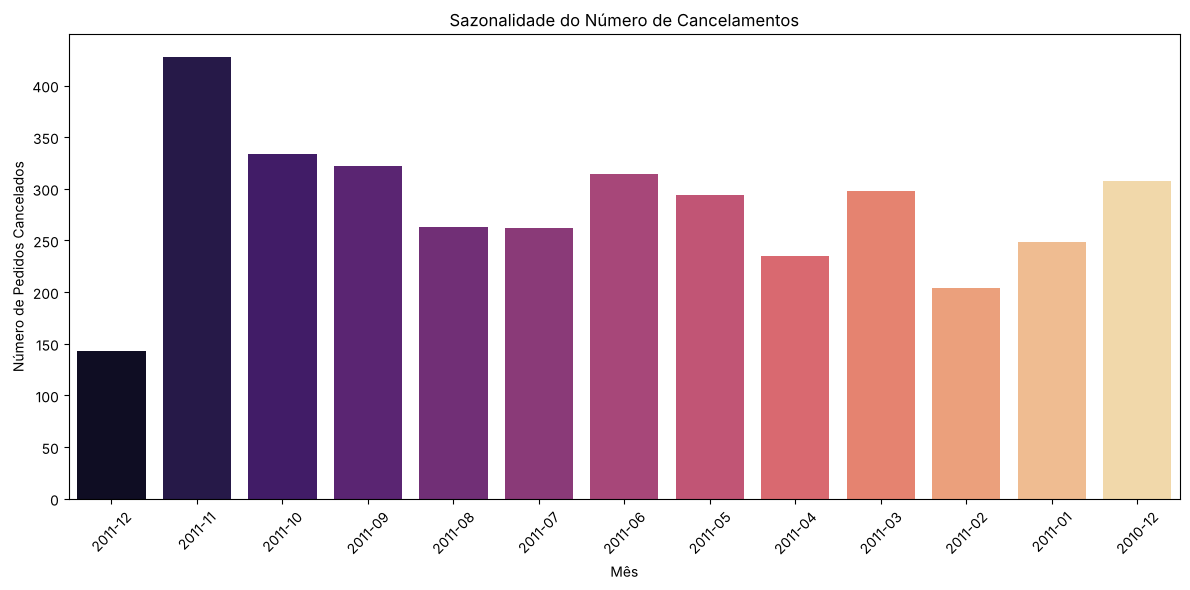

In [16]:
comparativo_mensal = pedidos_mensais.merge(cancelamentos_mensais, on='Mês', how='left').fillna({'Cancelamentos': 0})
display(comparativo_mensal.sort_values(by='Mês'))

posicoes = np.arange(len(comparativo_mensal))
largura = 0.35
plt.figure(figsize=(15, 7))
plt.bar(posicoes, comparativo_mensal['Nº Pedidos'], color='black', width=largura, label='Pedidos Totais')
plt.bar(posicoes + largura, comparativo_mensal['Cancelamentos'], color='red', width=largura, label='Pedidos Cancelados')
plt.xlabel('Mês', fontweight='bold')
plt.ylabel('Número de Pedidos', fontweight='bold')
plt.title('Comparativo: Pedidos Totais vs. Cancelamentos por Mês', fontweight='bold')
plt.xticks(posicoes + largura / 2, comparativo_mensal['Mês'], rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

for ordenacao, titulo in [('Cancelamentos', 'Número de Cancelamentos por Mês (do maior para o menor)'),
                          ('Mês', 'Sazonalidade do Número de Cancelamentos')]:
    grafico_de_barras(cancelamentos_mensais.sort_values(by=ordenacao, ascending=False), x='Mês', y='Cancelamentos', titulo=titulo,
                      rotulo_x='Mês', rotulo_y='Número de Pedidos Cancelados', paleta='magma', tamanho=(12, 6), girar_rotulos=True)

Top países por número de cancelamentos (excluindo Reino Unido):


,País,Nº de Cancelamentos
1,Germany,146
2,France,69
3,EIRE,59
4,Belgium,21
5,Switzerland,20
6,Italy,17
7,Spain,15
8,Portugal,13
9,Australia,12
10,Sweden,10


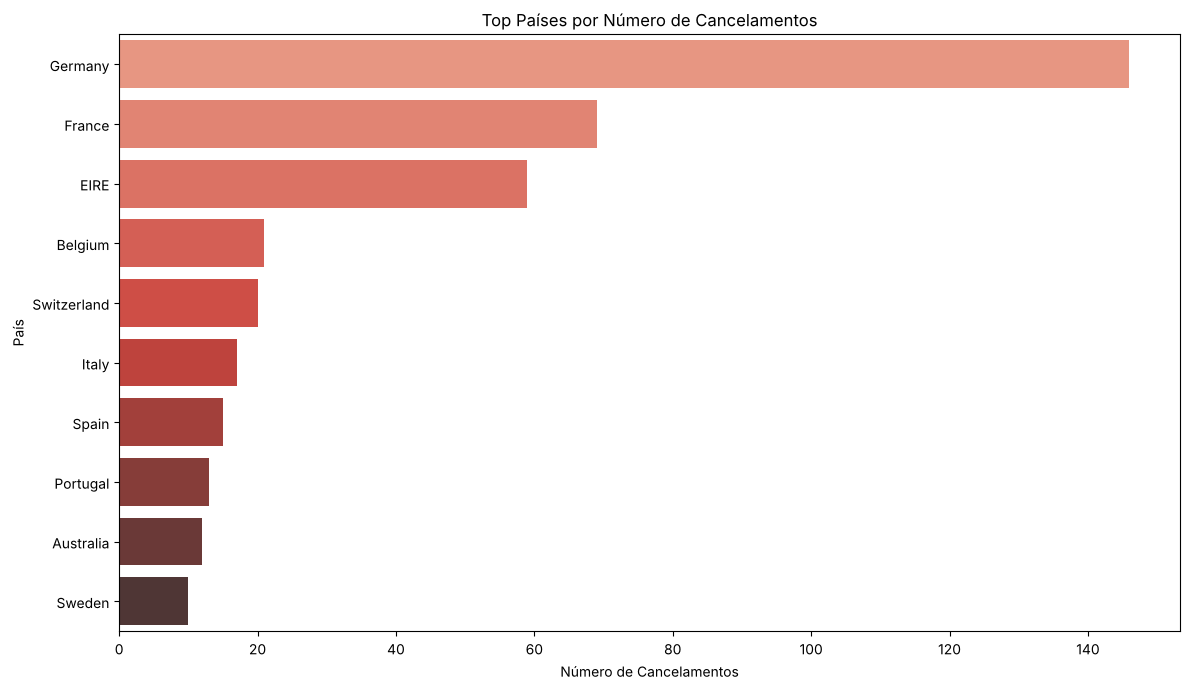

In [17]:
cancelamentos_por_pais = cancelados.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False).reset_index()
cancelamentos_por_pais.columns = ['País', 'Nº de Cancelamentos']
top_paises_cancelamento = sem_pais_sede(cancelamentos_por_pais, 'País').head(10)

print("Top países por número de cancelamentos (excluindo Reino Unido):")
display(top_paises_cancelamento)
grafico_de_barras(top_paises_cancelamento, x='Nº de Cancelamentos', y='País', titulo='Top Países por Número de Cancelamentos',
                  rotulo_x='Número de Cancelamentos', rotulo_y='País', paleta='Reds_d')

## Itens

15 itens mais cancelados:


,Descrição,Qnt
0,"PAPER CRAFT , LITTLE BIRDIE",80995
1,MEDIUM CERAMIC TOP STORAGE JAR,74494
2,ROTATING SILVER ANGELS T-LIGHT HLDR,9367
3,Manual,3995
4,FAIRY CAKE FLANNEL ASSORTED COLOUR,3150
5,PINK BLUE FELT CRAFT TRINKET BOX,2617
6,WHITE HANGING HEART T-LIGHT HOLDER,2578
7,GIN + TONIC DIET METAL SIGN,2030
8,HERB MARKER BASIL,1527
9,FELTCRAFT DOLL MOLLY,1447


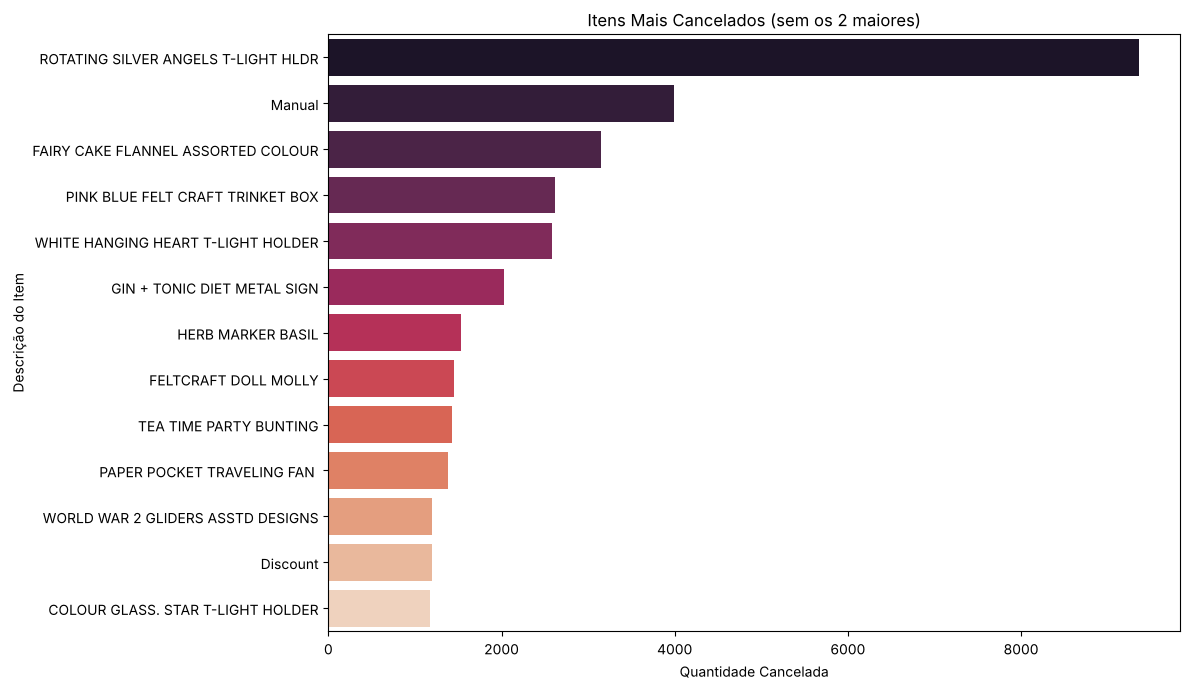

In [18]:
itens_mais_cancelados = top_itens(cancelados.groupby('Description')['Quantity'].sum().abs().sort_values(ascending=False), 15, 'Qnt')
print("15 itens mais cancelados:")
display(itens_mais_cancelados)

# Os dois primeiros têm um único cancelamento gigante (dezenas de milhares de unidades) e achatariam o gráfico
grafico_de_barras(itens_mais_cancelados.iloc[2:], x='Qnt', y='Descrição', titulo='Itens Mais Cancelados (sem os 2 maiores)',
                  rotulo_x='Quantidade Cancelada', rotulo_y='Descrição do Item', paleta='rocket')

In [19]:
preco_medio_por_item = vendas.groupby('Description')['UnitPrice'].mean().reset_index()

print("Estatísticas descritivas do preço unitário dos itens:")
display(preco_medio_por_item['UnitPrice'].describe())
print(f"Número total de itens únicos: {vendas['Description'].nunique()}")

Estatísticas descritivas do preço unitário dos itens:


count    3824.000000
mean        2.908813
std         2.788447
min         0.001000
25%         1.002679
50%         1.950000
75%         3.799476
max        15.000000
Name: UnitPrice, dtype: float64

Número total de itens únicos: 3824


10 itens mais comprados:


,Descrição,Qnt
0,ASSORTED COLOUR BIRD ORNAMENT,20002
1,WHITE HANGING HEART T-LIGHT HOLDER,18618
2,WORLD WAR 2 GLIDERS ASSTD DESIGNS,17023
3,PACK OF 72 RETROSPOT CAKE CASES,16293
4,JUMBO BAG RED RETROSPOT,14921
5,LUNCH BAG RED RETROSPOT,11597
6,PARTY BUNTING,10961
7,VICTORIAN GLASS HANGING T-LIGHT,10278
8,RABBIT NIGHT LIGHT,10194
9,HEART OF WICKER SMALL,10023


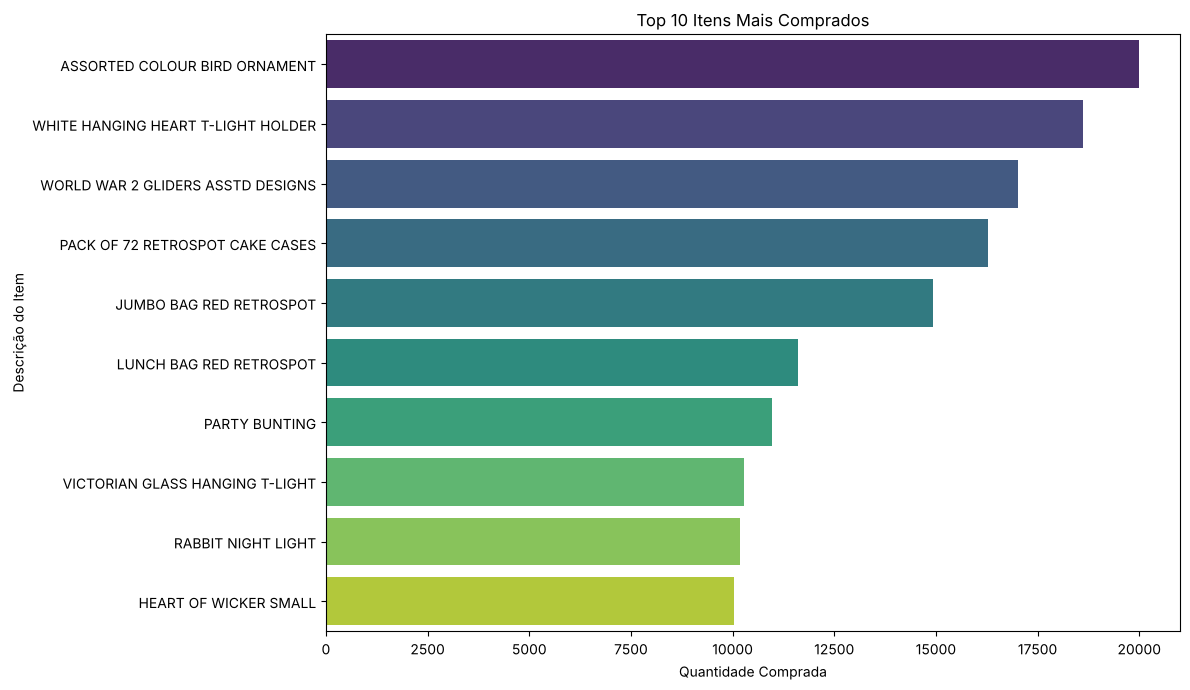

In [20]:
itens_mais_comprados = top_itens(vendas.groupby('Description')['Quantity'].sum().sort_values(ascending=False), 10, 'Qnt')
print("10 itens mais comprados:")
display(itens_mais_comprados)
grafico_de_barras(itens_mais_comprados, x='Qnt', y='Descrição', titulo='Top 10 Itens Mais Comprados',
                  rotulo_x='Quantidade Comprada', rotulo_y='Descrição do Item')

Top 10 Itens Mais Caros (Preço Médio):


,Description,UnitPrice
2157,Next Day Carriage,15.00
1655,I LOVE LONDON BABY GIFT SET,14.95
530,"BREAD BIN, DINER STYLE, IVORY",14.95
531,"BREAD BIN, DINER STYLE, MINT",14.95
1401,GLASS CAKE COVER AND PLATE,14.95
9,SPACEBOY BABY GIFT SET,14.95
768,CIRCUS PARADE BABY GIFT SET,14.95
3133,SILVER CHRISTMAS TREE BAUBLE STAND,14.95
972,DOLLY GIRL BABY GIFT SET,14.95
971,DOLLY CABINET 3 DRAWERS,14.95


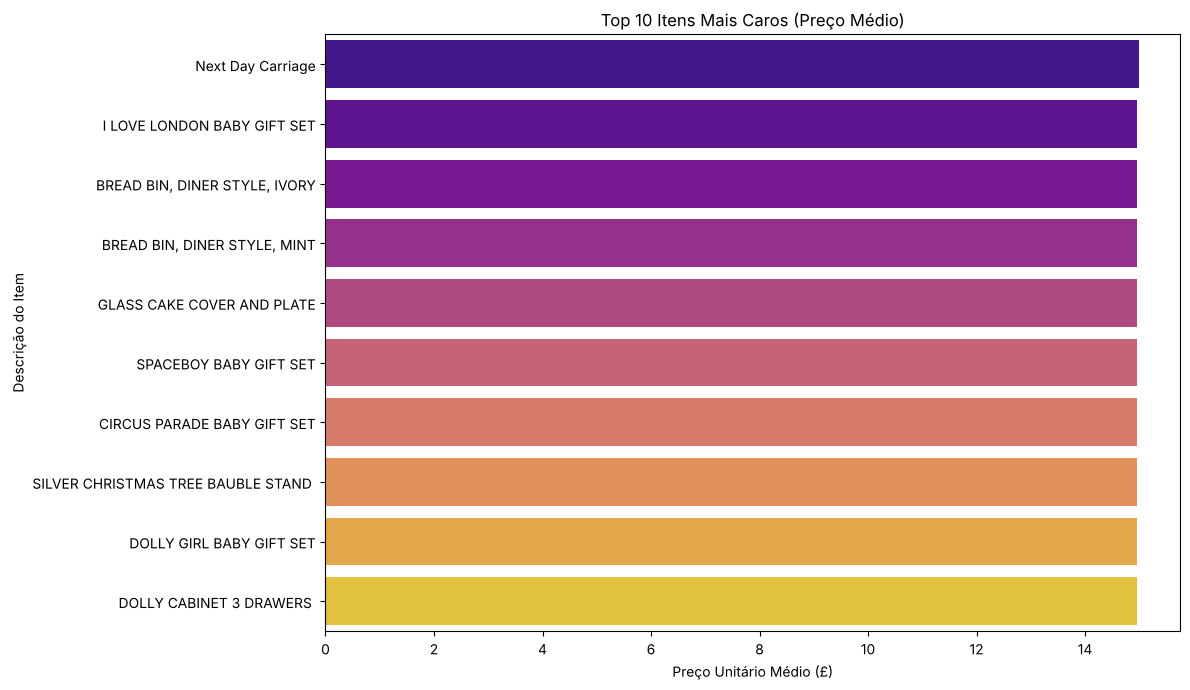

Top 10 Itens Mais Baratos (Preço Médio):


,Description,UnitPrice
2248,PADS TO MATCH ALL CUSHIONS,0.001000
2371,PIECE OF CAMO STATIONERY SET,0.080000
624,CARTOON PENCIL SHARPENERS,0.083529
1650,HOUSE SHAPE PENCIL SHARPENER,0.090000
2574,PORCELAIN BUDAH INCENSE HOLDER,0.100000
3748,WRAP BAD HAIR DAY,0.100000
485,BLUE STONES ON WIRE FOR CANDLE,0.100526
1881,LETTER SHAPE PENCIL SHARPENER,0.112500
2566,POP ART PUSH DOWN RUBBER,0.120000
1252,FOLDING CAMPING SCISSOR W/KNIF & S,0.120000


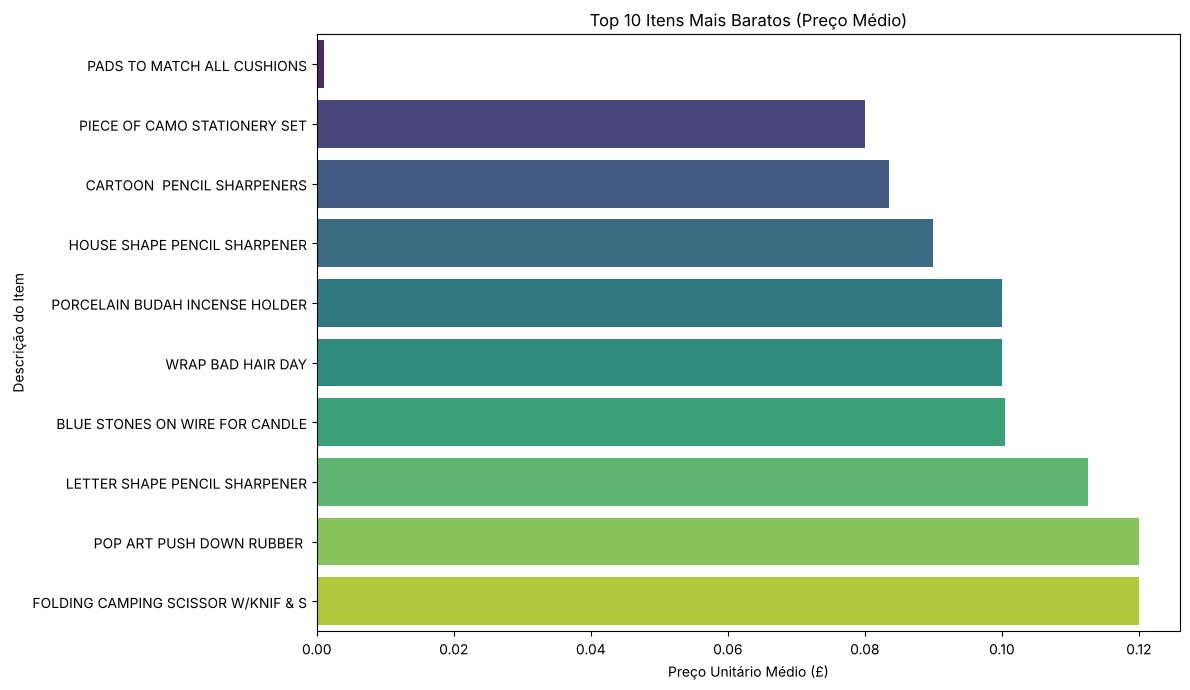

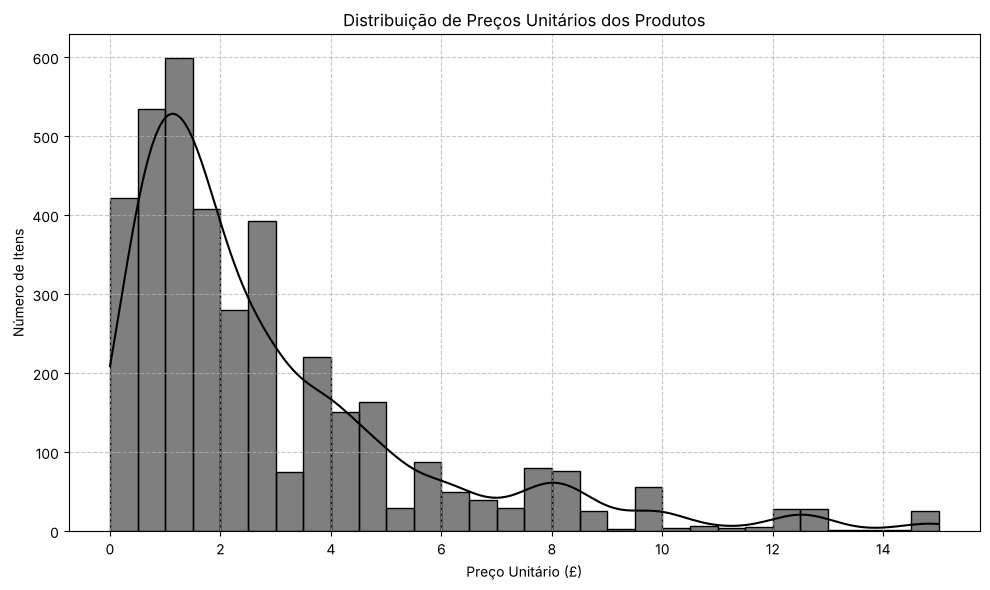

In [21]:
for crescente, titulo, paleta in [(False, 'Top 10 Itens Mais Caros (Preço Médio)', 'plasma'),
                                  (True, 'Top 10 Itens Mais Baratos (Preço Médio)', 'viridis')]:
    itens = preco_medio_por_item.sort_values(by='UnitPrice', ascending=crescente).head(10)
    print(f"{titulo}:")
    display(itens)
    grafico_de_barras(itens, x='UnitPrice', y='Description', titulo=titulo,
                      rotulo_x='Preço Unitário Médio (£)', rotulo_y='Descrição do Item', paleta=paleta)

plt.figure(figsize=(10, 6))
sns.histplot(preco_medio_por_item['UnitPrice'], bins=30, kde=True, color='black')
plt.title('Distribuição de Preços Unitários dos Produtos')
plt.xlabel('Preço Unitário (£)')
plt.ylabel('Número de Itens')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


--- United Kingdom: produtos mais lucrativos (receita média por venda) ---


,Description,Revenue
15198,CINDERELLA CHANDELIER,400.000000
14468,16 PIECE CUTLERY SET PANTRY DESIGN,300.000000
18112,WOODEN ADVENT CALENDAR CREAM,188.777778
17551,SILVER FLOWR PINK SHELL NECKLACE,111.760000
17573,SILVER T-LIGHT SETTING,106.390000


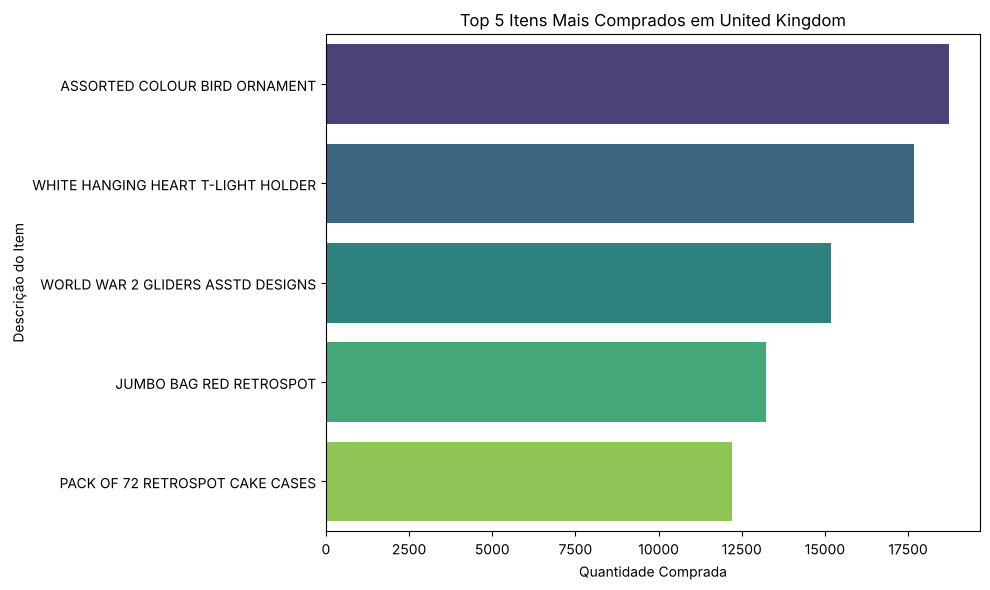


--- Germany: produtos mais lucrativos (receita média por venda) ---


,Description,Revenue
8060,SET OF 16 VINTAGE BLACK CUTLERY,262.800000
7030,CABIN BAG VINTAGE PAISLEY,153.000000
6991,BLUE SAVANNAH PICNIC HAMPER FOR 2,131.400000
7855,POMPOM CURTAIN,124.950000
7954,REGENCY CAKESTAND 3 TIER,122.707377


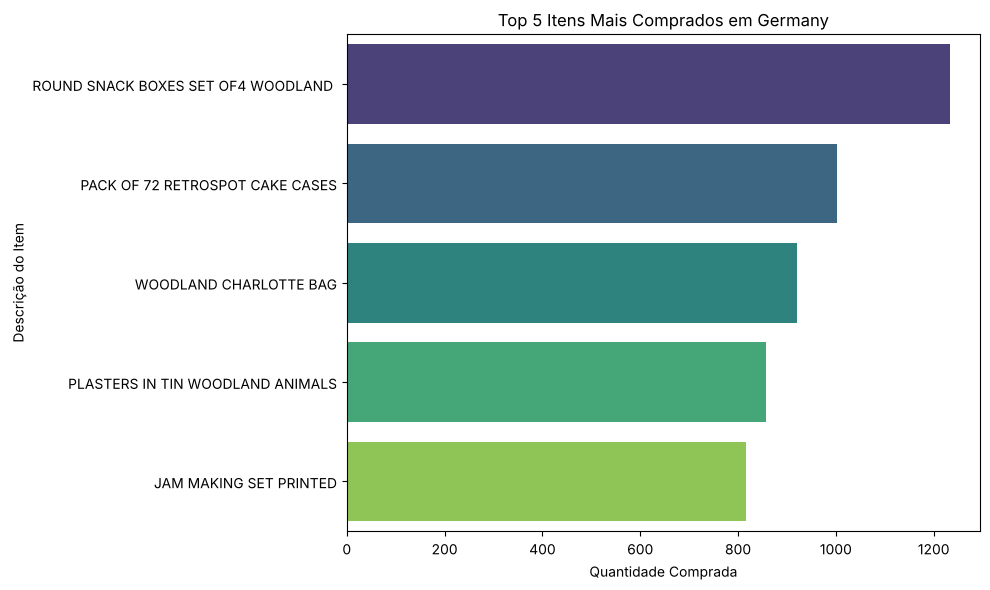


--- France: produtos mais lucrativos (receita média por venda) ---


,Description,Revenue
6183,PINK HAPPY BIRTHDAY BUNTING,232.500000
5851,I LOVE LONDON BABY GIFT SET,179.400000
5282,SPACEBOY BABY GIFT SET,140.957143
5577,CIRCUS PARADE BABY GIFT SET,119.600000
5630,DOLLY GIRL BABY GIFT SET,119.600000


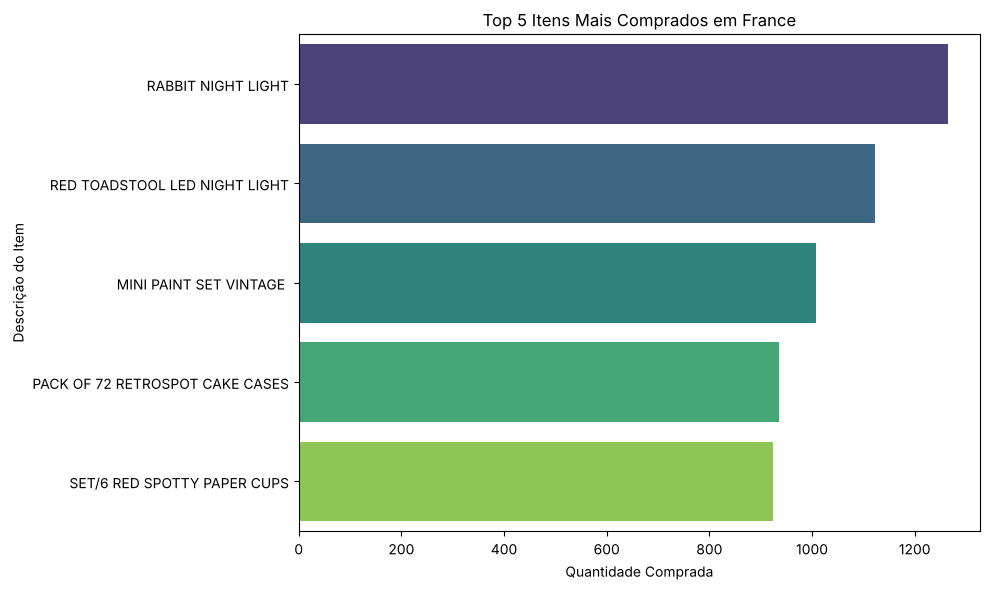


--- EIRE: produtos mais lucrativos (receita média por venda) ---


,Description,Revenue
2850,SPACEBOY BABY GIFT SET,358.800000
3227,CIRCUS PARADE BABY GIFT SET,269.100000
3324,DOLLY GIRL BABY GIFT SET,269.100000
2884,3 TIER CAKE TIN RED AND CREAM,255.378571
3778,LARGE DECO JEWELLERY STAND,220.066667


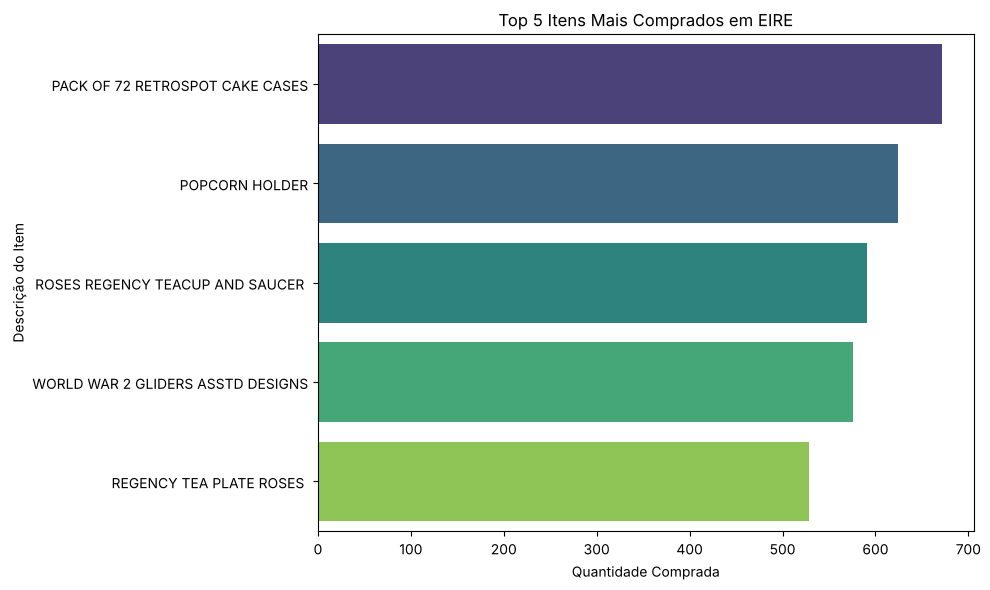


--- Switzerland: produtos mais lucrativos (receita média por venda) ---


,Description,Revenue
13286,16 PIECE CUTLERY SET PANTRY DESIGN,300.00
13999,SET OF 16 VINTAGE BLACK CUTLERY,262.80
13769,OPEN CLOSED METAL SIGN,153.00
13736,METAL SIGN TAKE IT OR LEAVE IT,122.40
14077,SMALL RED RETROSPOT MUG IN BOX,122.04


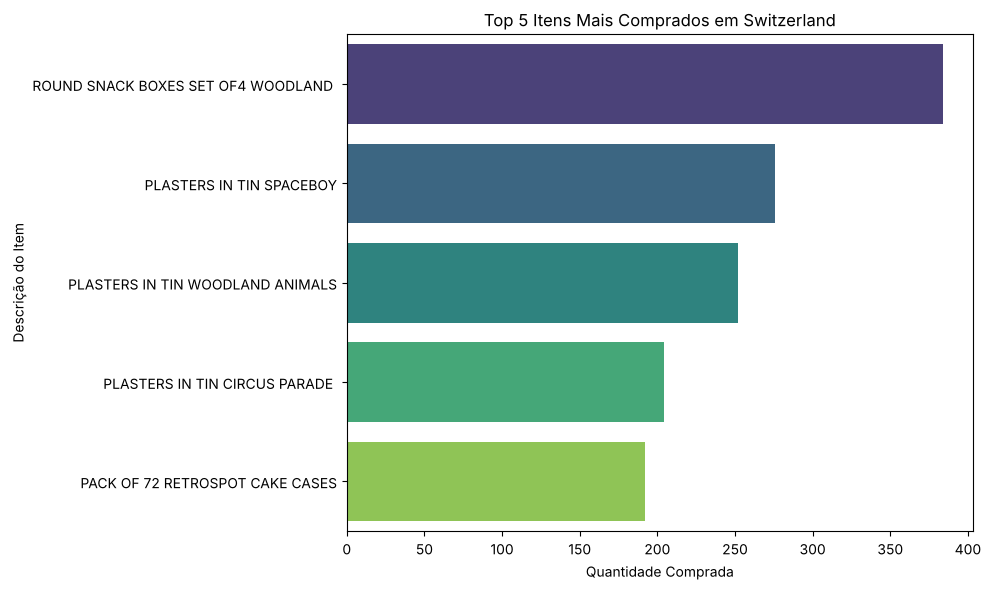

In [22]:
paises_que_mais_compram = vendas.groupby('Country')['Quantity'].sum().sort_values(ascending=False).head(5).index
quantidade_por_pais_e_item = vendas.groupby(['Country', 'Description'])['Quantity'].sum().reset_index()
receita_media_por_pais_e_item = vendas.groupby(['Country', 'Description'])['Revenue'].mean().reset_index()

for pais in paises_que_mais_compram:
    mais_comprados = quantidade_por_pais_e_item[quantidade_por_pais_e_item['Country'] == pais].nlargest(5, 'Quantity')
    mais_lucrativos = receita_media_por_pais_e_item[receita_media_por_pais_e_item['Country'] == pais].nlargest(5, 'Revenue')
    print(f"\n--- {pais}: produtos mais lucrativos (receita média por venda) ---")
    display(mais_lucrativos[['Description', 'Revenue']])
    grafico_de_barras(mais_comprados, x='Quantity', y='Description', titulo=f'Top 5 Itens Mais Comprados em {pais}',
                      rotulo_x='Quantidade Comprada', rotulo_y='Descrição do Item', tamanho=(10, 6))

Total de itens exclusivos de um país: 1013
Itens exclusivos fora do Reino Unido: 25


,Item,País,Quantidade Vendida
292,DOORKNOB CERAMIC IVORY,EIRE,36
206,CHRISTMAS CRAFT HEART STOCKING,Lithuania,30
93,BIRTHDAY BANNER TAPE,Switzerland,24
378,"GARLAND, MAGIC GARDEN 1.8M",EIRE,12
463,HOT WATER BOTTLE BABUSHKA LARGE,Switzerland,8
270,DAISY HAIR COMB,EIRE,6
95,BLACK 3 BEAD DROP EARRINGS,EIRE,6
42,ANT SILVER TURQUOISE BOUDICCA RING,Portugal,6
4,2 DAISIES HAIR COMB,EIRE,6
897,TINY CRYSTAL BRACELET GREEN,Germany,6


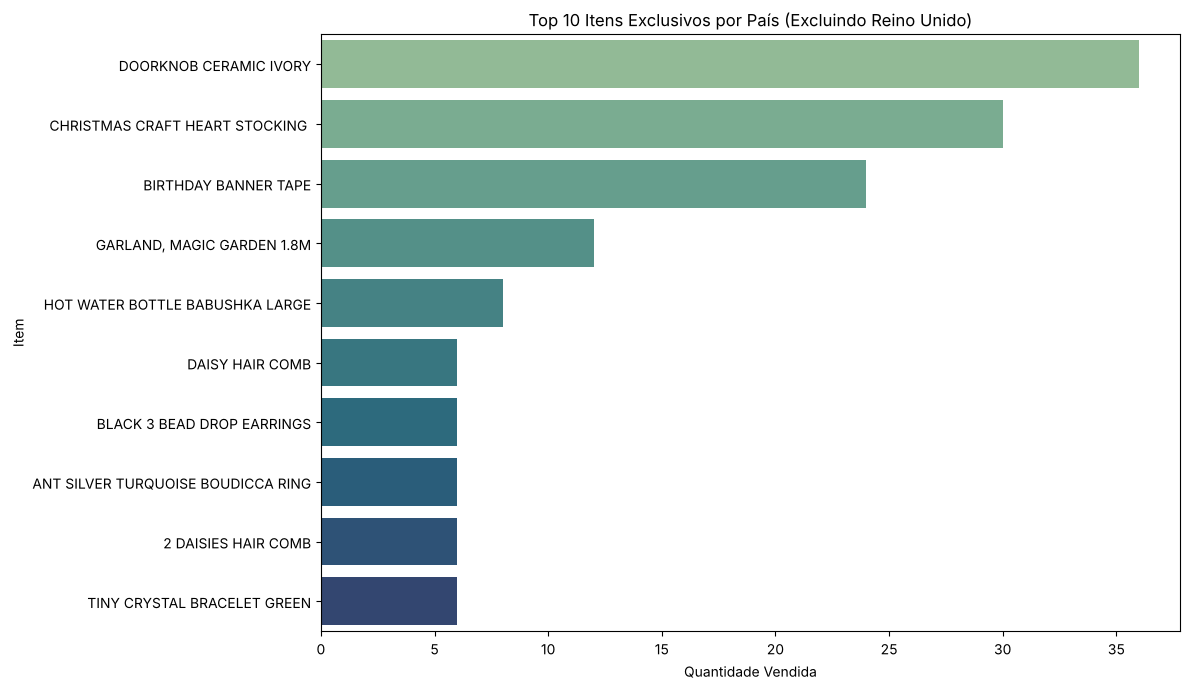

In [23]:
# Itens vendidos em apenas um país
paises_por_item = vendas.groupby('Description')['Country'].agg(['nunique', 'first'])
itens_exclusivos = paises_por_item[paises_por_item['nunique'] == 1]['first'].reset_index()
itens_exclusivos.columns = ['Item', 'País']
print(f"Total de itens exclusivos de um país: {len(itens_exclusivos)}")

vendas_dos_exclusivos = (vendas.merge(itens_exclusivos, left_on=['Description', 'Country'], right_on=['Item', 'País'])
                         .groupby(['Item', 'País'])['Quantity'].sum().reset_index(name='Quantidade Vendida'))
exclusivos_fora_da_sede = sem_pais_sede(vendas_dos_exclusivos, 'País').sort_values(by='Quantidade Vendida', ascending=False)
print(f"Itens exclusivos fora do Reino Unido: {len(exclusivos_fora_da_sede)}")
display(exclusivos_fora_da_sede.head(10))
grafico_de_barras(exclusivos_fora_da_sede.head(10), x='Quantidade Vendida', y='Item', titulo='Top 10 Itens Exclusivos por País (Excluindo Reino Unido)',
                  rotulo_x='Quantidade Vendida', rotulo_y='Item', paleta='crest')

In [24]:
# Itens baratos (menos de 1 por unidade) que quase não vendem: possível prejuízo de estoque
PRECO_BAIXO = 1
VENDAS_BAIXAS = 5

quantidade_dos_itens_baratos = vendas[vendas['UnitPrice'] < PRECO_BAIXO].groupby('Description')['Quantity'].sum().sort_values()
itens_baratos_parados = quantidade_dos_itens_baratos[quantidade_dos_itens_baratos <= VENDAS_BAIXAS]
print(f"Itens com preço menor que {PRECO_BAIXO} e no máximo {VENDAS_BAIXAS} unidades vendidas: {len(itens_baratos_parados)}")
display(top_itens(itens_baratos_parados, len(itens_baratos_parados), 'Quantidade Vendida'))

Itens com preço menor que 1 e no máximo 5 unidades vendidas: 23


,Descrição,Quantidade Vendida
0,3 BIRDS CANVAS SCREEN,1
1,Bank Charges,1
2,PINK CRYSTAL GUITAR PHONE CHARM,1
3,SET OF PICTURE FRAME STICKERS,1
4,MINT KITCHEN SCALES,1
5,SET 12 COLOURING PENCILS DOILEY,1
6,PURPLE FRANGIPANI HAIRCLIP,1
7,HEN HOUSE W CHICK IN NEST,1
8,PACK 20 DOLLY PEGS,2
9,60 GOLD AND SILVER FAIRY CAKE CASES,2


## Clientes

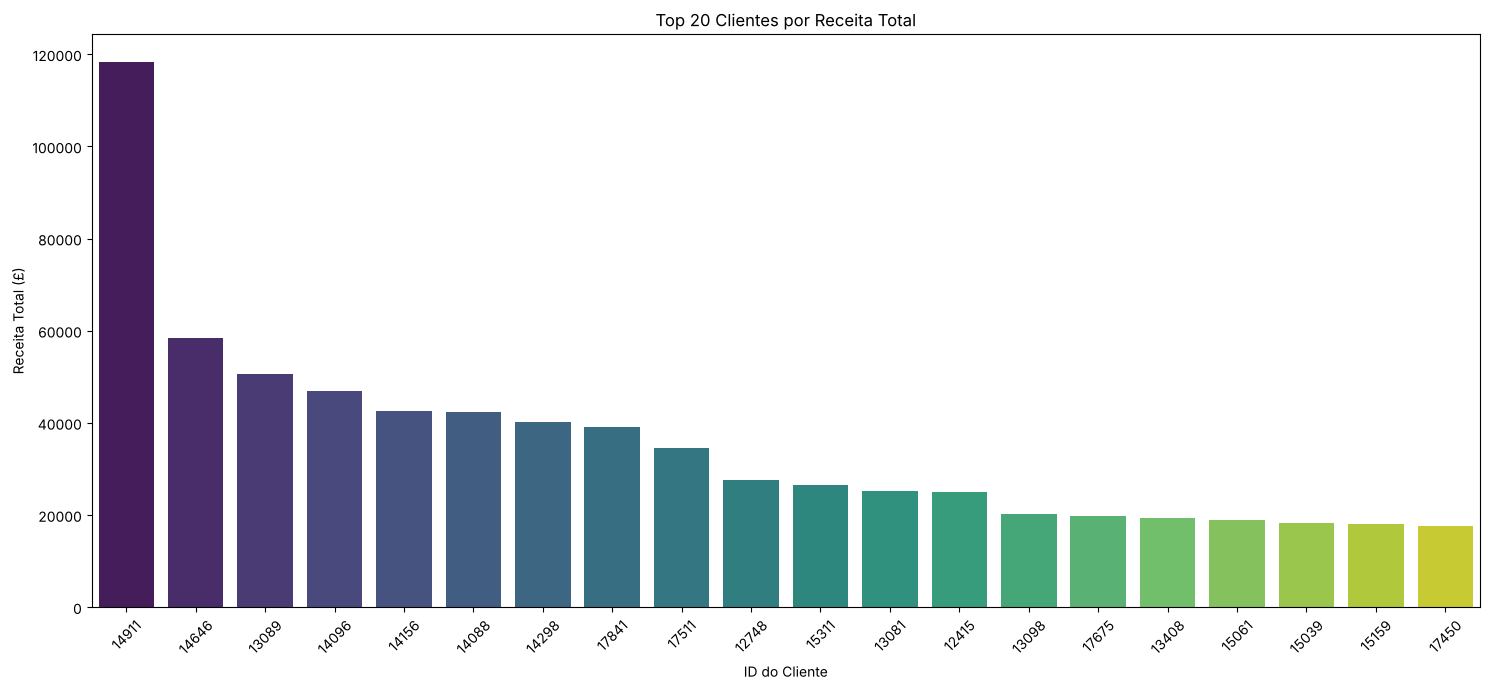

,CustomerID,Revenue,% Receita Acumulada,% Clientes
0,16446.0,2.90,0.000049,0.023491
1,16738.0,3.75,0.000111,0.046981
2,16429.0,4.95,0.000194,0.070472
3,14792.0,6.20,0.000298,0.093963
4,16454.0,6.90,0.000414,0.117454


In [25]:
receita_por_cliente = vendas.groupby('CustomerID')['Revenue'].sum().reset_index()
top_clientes = receita_por_cliente.nlargest(20, 'Revenue')
top_clientes['CustomerID'] = top_clientes['CustomerID'].astype(int).astype(str)

grafico_de_barras(top_clientes, x='CustomerID', y='Revenue', titulo='Top 20 Clientes por Receita Total',
                  rotulo_x='ID do Cliente', rotulo_y='Receita Total (£)', tamanho=(15, 7), girar_rotulos=True)

# Concentração de receita: % acumulada de receita contra % acumulada de clientes (base da curva de Lorenz)
concentracao = receita_por_cliente.sort_values(by='Revenue').reset_index(drop=True)
concentracao['% Receita Acumulada'] = concentracao['Revenue'].cumsum() / concentracao['Revenue'].sum() * 100
concentracao['% Clientes'] = (concentracao.index + 1) / len(concentracao) * 100
display(concentracao.head())

### Análise RFM (Recência, Frequência, Valor Monetário)

In [26]:
rfm = calcular_rfm(vendas, vendas['InvoiceDate'].max())

# Notas de 1 a 5 por quintil. Recência: quanto menor, melhor (nota invertida)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['RFM_Score'] = rfm['R_Score'] + rfm['F_Score'] + rfm['M_Score']
display(rfm.head())

,ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12347.0,1,7,4060.40,5,5,5,15
1,12348.0,248,3,200.60,1,3,1,5
2,12349.0,18,1,1353.80,4,1,4,9
3,12350.0,309,1,294.40,1,1,2,4
4,12352.0,35,7,1385.74,3,5,4,12


,Segmento,Número de Clientes
0,Melhores Clientes,2225
1,Clientes Potenciais,753
2,Clientes Leais,741
3,Clientes em Risco,538


,Recência,Frequência,Valor_Médio,Clientes
Segmento,,,,
Clientes Leais,91.0,1.8,512.6,741
Clientes Potenciais,147.8,1.2,306.5,753
Clientes em Risco,251.2,1.0,169.4,538
Melhores Clientes,34.0,6.7,2368.2,2225


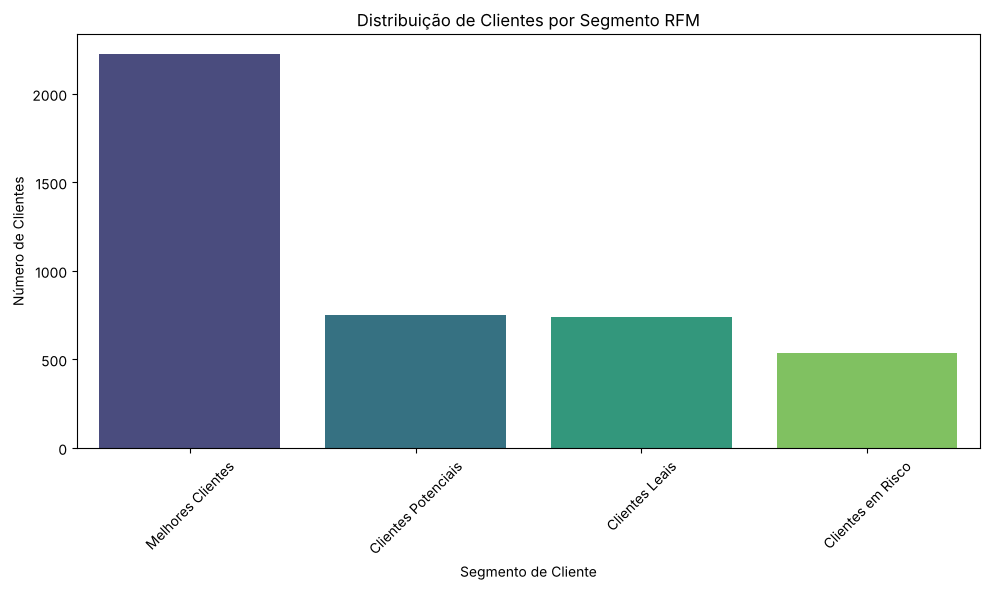

In [27]:
def segmento_rfm(pontuacao):
    if pontuacao >= 9:
        return 'Melhores Clientes'
    if pontuacao >= 7:
        return 'Clientes Leais'
    if pontuacao >= 5:
        return 'Clientes Potenciais'
    return 'Clientes em Risco'


rfm['Segmento'] = rfm['RFM_Score'].apply(segmento_rfm)
clientes_por_segmento = rfm['Segmento'].value_counts().reset_index()
clientes_por_segmento.columns = ['Segmento', 'Número de Clientes']
display(clientes_por_segmento)

display(rfm.groupby('Segmento').agg(Recência=('Recency', 'mean'), Frequência=('Frequency', 'mean'),
                                    Valor_Médio=('Monetary', 'mean'), Clientes=('ID', 'count')).round(1))

grafico_de_barras(clientes_por_segmento, x='Segmento', y='Número de Clientes', titulo='Distribuição de Clientes por Segmento RFM',
                  rotulo_x='Segmento de Cliente', rotulo_y='Número de Clientes', tamanho=(10, 6), girar_rotulos=True)

## Sugestões Iniciais

Informações encontradas na análise exploratória

- A média de preço dos itens vendidos é £2,91.
- Ticket médio é de £338.77.
- Os meses com menos vendas são de dezembro a abril.
- Existem 25 itens que não são vendidos no Reino Unido mas são vendidos em outros países.
- Dos 3824 itens existentes, 1023 são vendidos em apenas um país (998 sendo no Reino Unido).
- O país com maior lucratividade fora do Reino Unido é Alemanha, seguida da França.
- O número de clientes em potencial é próximo do de clientes leais.
- Existem 538 clientes em risco.
- "PACK OF 72 RETROSPOT CAKE CASES" é um dos itens mais vendido em vários países.
- Existem 23 itens com potencial risco de prejuízo no estoque, pois vendem 5 ou menos unidades por ano e custam menos de 1 euro.

Questões iniciais para a gerência analisar
- Avaliar questões de sazonalidade: o que causa das vendas menores entre dezembro e abril?
- Quais os principais motivos de cancelamento?
- Todas as lojas estão dando lucro? Qual o custo operacional das 5 lojas que menos faturam?
- Quais produtos não estão vendendo ou geram mais custo de estoque do que lucro?

# Modelagem Preditiva

A pergunta é se o cliente volta a comprar nos próximos 60 dias. Os dados são divididos no tempo:

- **Janela de observação:** tudo até 60 dias antes da última data. Só ela é usada para calcular as variáveis dos clientes, para não vazar informação do futuro.
- **Janela de previsão:** os últimos 60 dias. Define o alvo: 1 se o cliente comprou nesse período, 0 se não.

In [28]:
data_final = vendas['InvoiceDate'].max()
inicio_da_previsao = data_final - pd.DateOffset(days=JANELA_DE_PREVISAO_DIAS)
observacao = vendas[vendas['InvoiceDate'] <= inicio_da_previsao]
previsao = vendas[vendas['InvoiceDate'] > inicio_da_previsao]

alvo = pd.DataFrame({'ID': observacao['CustomerID'].unique()})
alvo['Repurchase_60_Days'] = alvo['ID'].isin(previsao['CustomerID'].unique()).astype(int)

print(f"Data mais recente no dataset: {data_final}")
print(f"Início da janela de previsão: {inicio_da_previsao}")
print(f"Transações na janela de observação: {len(observacao)}")
print(f"Transações na janela de previsão: {len(previsao)}")
print("Distribuição do alvo (recompra em 60 dias):")
display(alvo['Repurchase_60_Days'].value_counts())

Data mais recente no dataset: 2011-12-09 12:50:00
Início da janela de previsão: 2011-10-10 12:50:00
Transações na janela de observação: 269334
Transações na janela de previsão: 113527
Distribuição do alvo (recompra em 60 dias):


Repurchase_60_Days
0    1898
1    1756
Name: count, dtype: int64

## Etapa 1 de testes: RFM

Recência, frequência e valor monetário de cada cliente, calculados só na janela de observação.

In [29]:
rfm_observacao = calcular_rfm(observacao, observacao['InvoiceDate'].max(), sufixo='_obs')
base_rfm = alvo.merge(rfm_observacao, on='ID', how='left')
VARIAVEIS_RFM = ['Recency_obs', 'Frequency_obs', 'Monetary_obs']
X_rfm = base_rfm[VARIAVEIS_RFM]
divisao_rfm = dividir_treino_e_teste(X_rfm, base_rfm['Repurchase_60_Days'])
display(base_rfm.head())

,ID,Repurchase_60_Days,Recency_obs,Frequency_obs,Monetary_obs
0,17850.0,0,311,34,4783.46
1,13047.0,1,66,8,2682.01
2,12583.0,1,9,11,4273.15
3,15100.0,0,273,3,876.00
4,15291.0,1,34,10,2619.06


### Regressão Logística

Relatório de Classificação (Regressão Logística - RFM):
              precision    recall  f1-score   support

           0       0.65      0.77      0.71       380
           1       0.69      0.55      0.61       351

    accuracy                           0.67       731
   macro avg       0.67      0.66      0.66       731
weighted avg       0.67      0.67      0.66       731

Acurácia: 0.6676
Precisão (Classe 1): 0.6929
Recall (Classe 1): 0.5527
F1-Score (Classe 1): 0.6149
ROC AUC Score: 0.7267


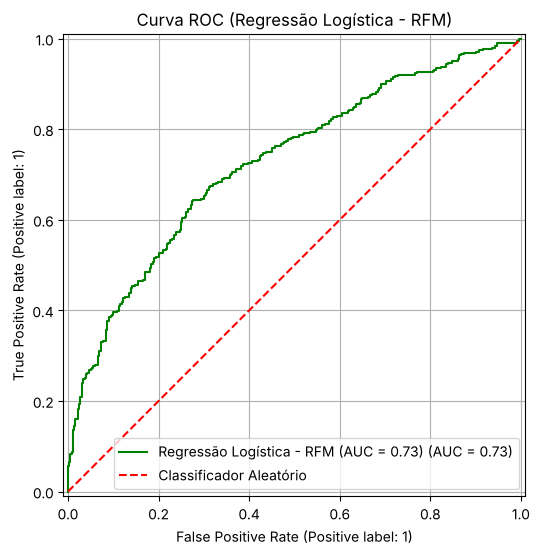

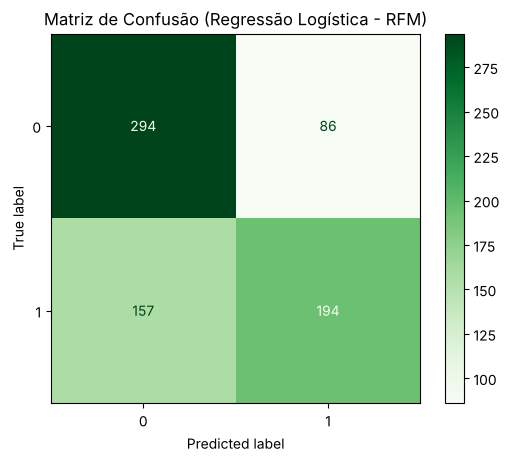

,Variável,Coeficiente
1,Frequency_obs,0.204989
0,Recency_obs,-0.003652
2,Monetary_obs,0.000328


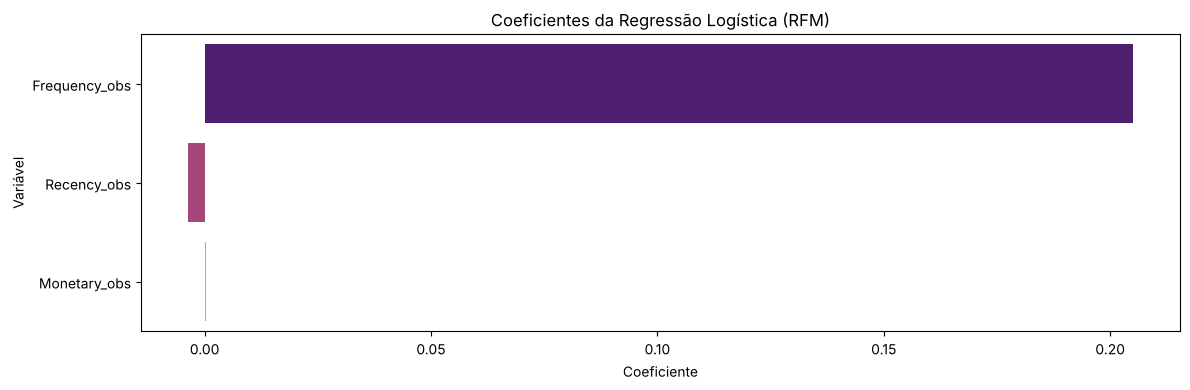

In [30]:
logistica_rfm = regressao_logistica()
resultados = {'Logística (RFM)': treinar_e_avaliar(logistica_rfm, 'Regressão Logística - RFM', divisao_rfm, cor='green', mapa_de_cores=plt.cm.Greens)}
importancia_das_variaveis(logistica_rfm, VARIAVEIS_RFM, 'Coeficientes da Regressão Logística (RFM)', paleta='magma');

### Random Forest

Relatório de Classificação (Random Forest - RFM):
              precision    recall  f1-score   support

           0       0.62      0.68      0.65       380
           1       0.62      0.55      0.58       351

    accuracy                           0.62       731
   macro avg       0.62      0.62      0.62       731
weighted avg       0.62      0.62      0.62       731

Acurácia: 0.6197
Precisão (Classe 1): 0.6159
Recall (Classe 1): 0.5527
F1-Score (Classe 1): 0.5826
ROC AUC Score: 0.6782


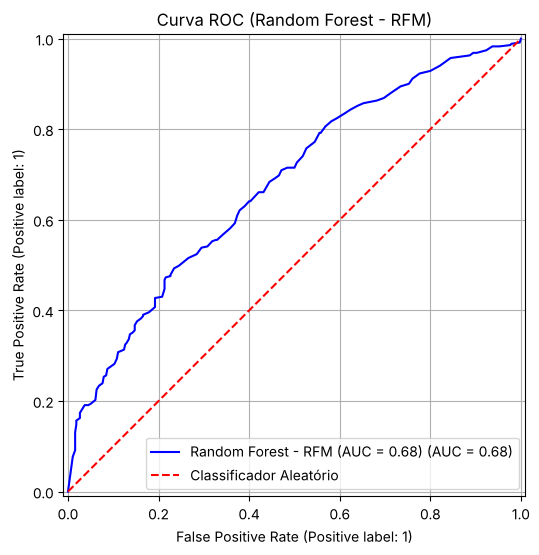

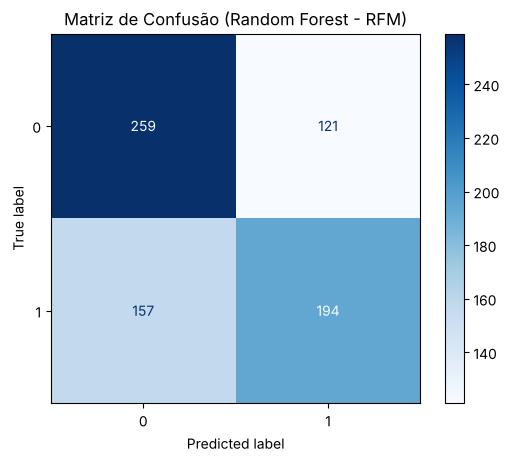

,Variável,Importância
2,Monetary_obs,0.50392
0,Recency_obs,0.37221
1,Frequency_obs,0.12387


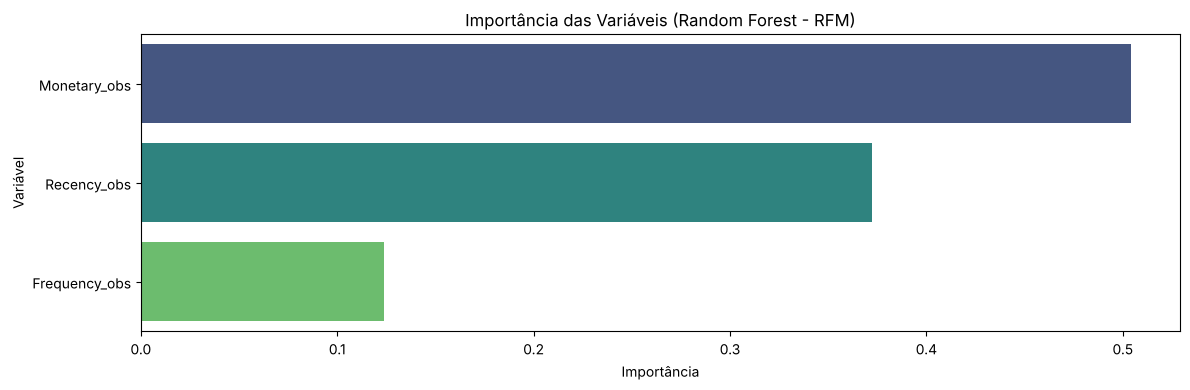

In [31]:
floresta_rfm = floresta_aleatoria()
resultados['Random Forest (RFM)'] = treinar_e_avaliar(floresta_rfm, 'Random Forest - RFM', divisao_rfm)
importancia_das_variaveis(floresta_rfm, VARIAVEIS_RFM, 'Importância das Variáveis (Random Forest - RFM)');

In [32]:
COLUNAS_DA_PRIORIZACAO = ['ID'] + VARIAVEIS_RFM + ['Probabilidade', 'Repurchase_60_Days']
clientes_priorizados = priorizar_clientes(logistica_rfm, X_rfm, base_rfm, 'Probabilidade')
print("Clientes priorizados pela probabilidade de recompra nos próximos 60 dias (Regressão Logística - RFM):")
display(clientes_priorizados[COLUNAS_DA_PRIORIZACAO].head(10))

Clientes priorizados pela probabilidade de recompra nos próximos 60 dias (Regressão Logística - RFM):


,ID,Recency_obs,Frequency_obs,Monetary_obs,Probabilidade,Repurchase_60_Days
62,14911.0,0,133,78552.24,1.0,1
43,12748.0,1,143,17826.19,1.0,1
225,13089.0,3,77,40195.24,1.0,1
66,17841.0,3,94,25476.99,1.0,1
822,14646.0,4,41,44237.97,1.0,1
7,15311.0,3,72,20656.71,1.0,1
192,14156.0,10,37,36795.89,1.0,1
87,14606.0,0,78,9334.36,1.0,1
672,14298.0,11,37,34226.85,1.0,1
160,12971.0,5,67,7518.17,1.0,1


## Etapa 2 de testes: variáveis expandidas

Vamos calcular as novas variáveis agregadas por cliente para a janela de observação (`observacao`):

*   **Quantidade Total de Itens Comprados (`TotalQuantity_obs`):** Soma das quantidades de todos os itens comprados.
*   **Diversidade de Produtos (`UniqueItemsPurchased_obs`):** Número de produtos únicos comprados por cliente.
*   **País Principal (`MainCountry_obs`):** O país de onde o cliente realizou a maioria de suas compras.
*   **Taxa de Cancelamento (`CancellationRate_obs`):** Proporção de pedidos cancelados pelo cliente na janela de observação.
*   **Média de Dias entre Pedidos (`AvgDaysBetweenOrders_obs`):** Média do tempo (em dias) entre as compras consecutivas do cliente.

In [33]:
def media_de_dias_entre_compras(datas):
    """Média de dias entre transações consecutivas do cliente (0 se houver só uma)."""
    if len(datas) < 2:
        return 0
    return datas.sort_values().diff().dropna().dt.days.mean()


cancelados_na_observacao = cancelados[cancelados['InvoiceDate'] <= inicio_da_previsao]
pedidos_cancelados = cancelados_na_observacao.groupby('CustomerID')['InvoiceNo'].nunique()

variaveis_extras = observacao.groupby('CustomerID').agg(
    TotalQuantity_obs=('Quantity', 'sum'),
    UniqueItemsPurchased_obs=('StockCode', 'nunique'),
    MainCountry_obs=('Country', lambda paises: paises.mode()[0]),
    AvgDaysBetweenOrders_obs=('InvoiceDate', media_de_dias_entre_compras),
    TotalOrders_obs=('InvoiceNo', 'nunique'),
)
variaveis_extras['CancellationRate_obs'] = pedidos_cancelados.reindex(variaveis_extras.index, fill_value=0) / variaveis_extras['TotalOrders_obs']
variaveis_extras = variaveis_extras.drop(columns='TotalOrders_obs').reset_index().rename(columns={'CustomerID': 'ID'})

COLUNAS_EXPANDIDAS = VARIAVEIS_RFM + ['TotalQuantity_obs', 'UniqueItemsPurchased_obs', 'MainCountry_obs',
                                      'CancellationRate_obs', 'AvgDaysBetweenOrders_obs']
base_expandida = base_rfm.merge(variaveis_extras, on='ID', how='left')[['ID', 'Repurchase_60_Days'] + COLUNAS_EXPANDIDAS]
base_expandida = pd.get_dummies(base_expandida, columns=['MainCountry_obs'], prefix='Country')

X_expandido = base_expandida.drop(columns=['ID', 'Repurchase_60_Days'])
divisao_expandida = dividir_treino_e_teste(X_expandido, base_expandida['Repurchase_60_Days'])
print(f"Variáveis utilizadas ({X_expandido.shape[1]}): {X_expandido.columns.tolist()}")

Variáveis utilizadas (43): ['Recency_obs', 'Frequency_obs', 'Monetary_obs', 'TotalQuantity_obs', 'UniqueItemsPurchased_obs', 'CancellationRate_obs', 'AvgDaysBetweenOrders_obs', 'Country_Australia', 'Country_Austria', 'Country_Bahrain', 'Country_Belgium', 'Country_Brazil', 'Country_Canada', 'Country_Channel Islands', 'Country_Cyprus', 'Country_Czech Republic', 'Country_Denmark', 'Country_EIRE', 'Country_European Community', 'Country_Finland', 'Country_France', 'Country_Germany', 'Country_Greece', 'Country_Iceland', 'Country_Israel', 'Country_Italy', 'Country_Japan', 'Country_Lebanon', 'Country_Lithuania', 'Country_Malta', 'Country_Netherlands', 'Country_Norway', 'Country_Poland', 'Country_Portugal', 'Country_Saudi Arabia', 'Country_Singapore', 'Country_Spain', 'Country_Sweden', 'Country_Switzerland', 'Country_USA', 'Country_United Arab Emirates', 'Country_United Kingdom', 'Country_Unspecified']


Relatório de Classificação (Logística (Expandida)):
              precision    recall  f1-score   support

           0       0.65      0.78      0.71       380
           1       0.70      0.55      0.62       351

    accuracy                           0.67       731
   macro avg       0.68      0.67      0.66       731
weighted avg       0.67      0.67      0.67       731

Acurácia: 0.6703
Precisão (Classe 1): 0.6978
Recall (Classe 1): 0.5527
F1-Score (Classe 1): 0.6169
ROC AUC Score: 0.7308


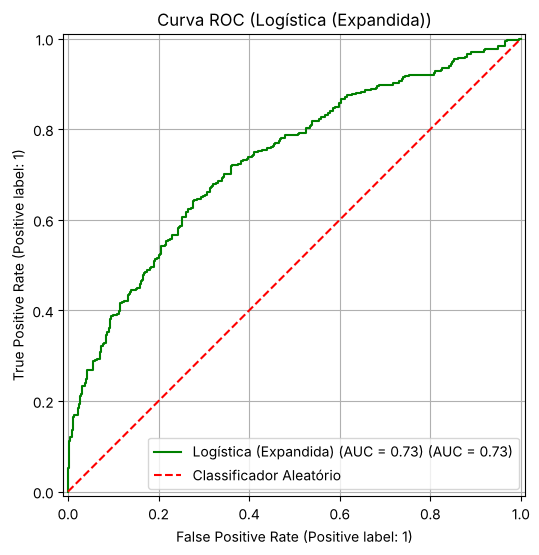

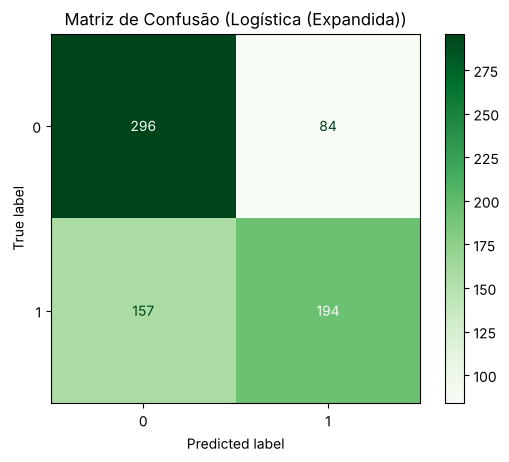

Relatório de Classificação (Random Forest (Expandida)):
              precision    recall  f1-score   support

           0       0.65      0.74      0.69       380
           1       0.67      0.56      0.61       351

    accuracy                           0.65       731
   macro avg       0.66      0.65      0.65       731
weighted avg       0.66      0.65      0.65       731

Acurácia: 0.6539
Precisão (Classe 1): 0.6655
Recall (Classe 1): 0.5613
F1-Score (Classe 1): 0.6090
ROC AUC Score: 0.7041


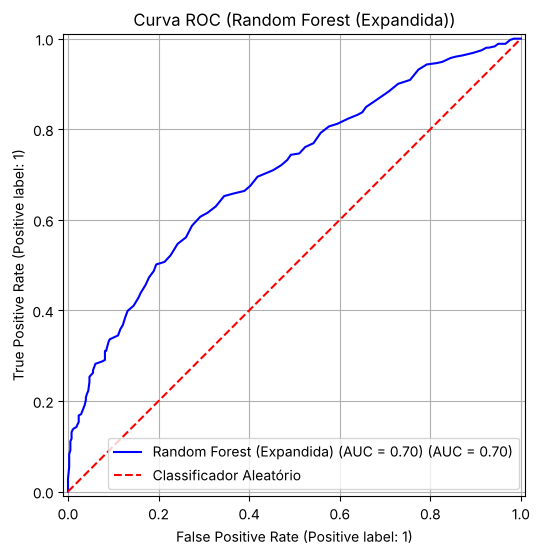

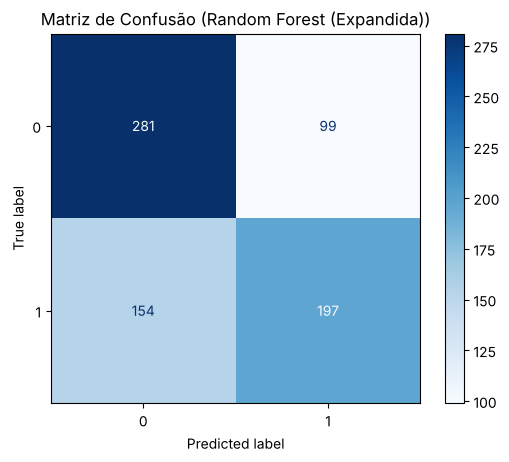

Relatório de Classificação (Árvore de Decisão (Expandida)):
              precision    recall  f1-score   support

           0       0.58      0.60      0.59       380
           1       0.55      0.53      0.54       351

    accuracy                           0.57       731
   macro avg       0.57      0.57      0.57       731
weighted avg       0.57      0.57      0.57       731

Acurácia: 0.5677
Precisão (Classe 1): 0.5519
Recall (Classe 1): 0.5299
F1-Score (Classe 1): 0.5407
ROC AUC Score: 0.5663


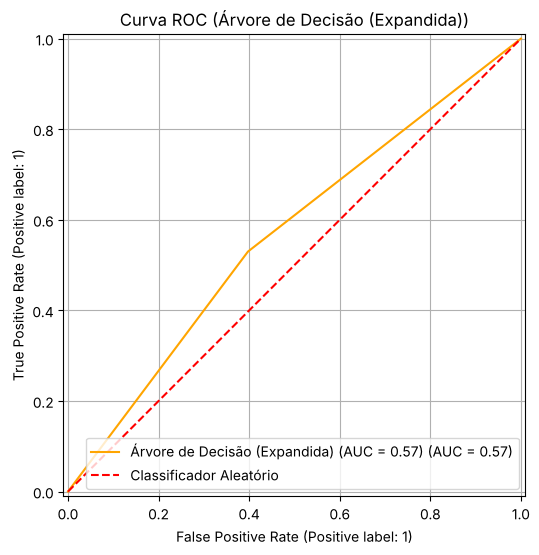

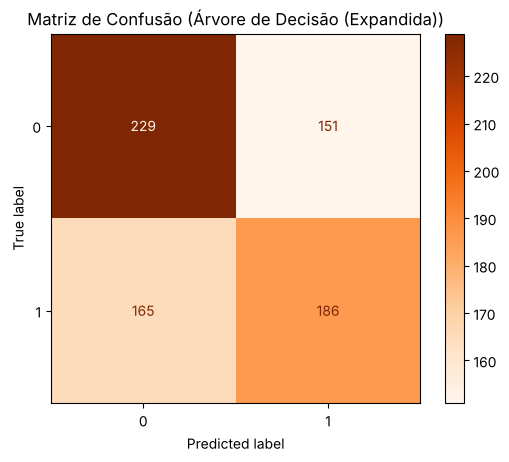

Relatório de Classificação (LightGBM (Expandida)):
              precision    recall  f1-score   support

           0       0.63      0.72      0.67       380
           1       0.64      0.55      0.59       351

    accuracy                           0.64       731
   macro avg       0.64      0.63      0.63       731
weighted avg       0.64      0.64      0.63       731

Acurácia: 0.6361
Precisão (Classe 1): 0.6412
Recall (Classe 1): 0.5499
F1-Score (Classe 1): 0.5920
ROC AUC Score: 0.6935


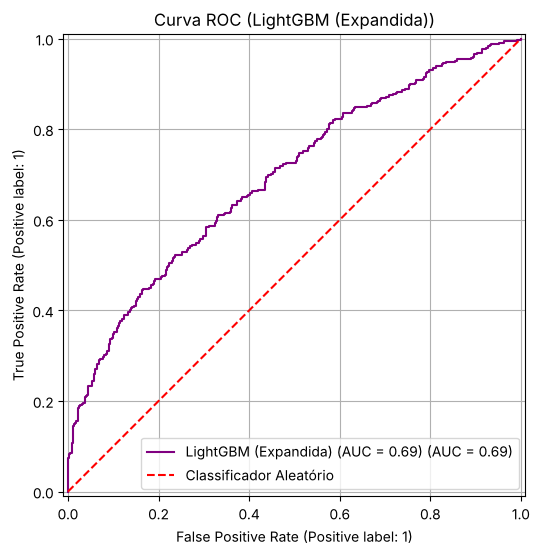

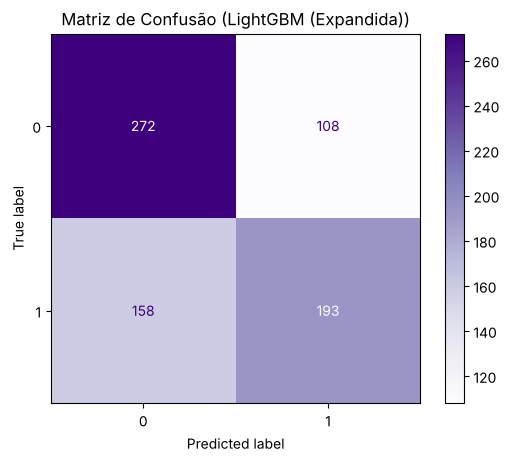

Métrica,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1),ROC AUC Score
Logística (Expandida),0.6703,0.6978,0.5527,0.6169,0.7308
Random Forest (Expandida),0.6539,0.6655,0.5613,0.6090,0.7041
Árvore de Decisão (Expandida),0.5677,0.5519,0.5299,0.5407,0.5663
LightGBM (Expandida),0.6361,0.6412,0.5499,0.5920,0.6935


O melhor modelo com base no F1-Score da classe 1 é: Logística (Expandida) com F1-Score: 0.6169


In [34]:
logistica_expandida = regressao_logistica()
modelos_expandidos = [
    ('Logística (Expandida)', logistica_expandida, 'green', plt.cm.Greens),
    ('Random Forest (Expandida)', floresta_aleatoria(), 'blue', plt.cm.Blues),
    ('Árvore de Decisão (Expandida)', arvore_de_decisao(), 'orange', plt.cm.Oranges),
    ('LightGBM (Expandida)', lightgbm(), 'purple', plt.cm.Purples),
]
for nome, modelo, cor, mapa in modelos_expandidos:
    resultados[nome] = treinar_e_avaliar(modelo, nome, divisao_expandida, cor=cor, mapa_de_cores=mapa)

comparar_modelos({nome: resultados[nome] for nome, *_ in modelos_expandidos});

### Seleção de Variáveis Melhorada

Com base nas importâncias das features (coeficientes) da Regressão Logística com features expandidas, podemos fazer uma seleção de variáveis para simplificar o modelo e potencialmente melhorar o desempenho, focando nos fatores mais relevantes.

Vamos identificar as features com os maiores valores absolutos de coeficientes para incluí-las no modelo.

,Variável,Coeficiente
38,Country_Switzerland,-0.358483
7,Country_Australia,-0.260284
5,CancellationRate_obs,0.254426
31,Country_Norway,0.220764
24,Country_Israel,-0.216240
1,Frequency_obs,0.201388
21,Country_Germany,0.194759
42,Country_Unspecified,-0.187853
25,Country_Italy,0.177923
32,Country_Poland,-0.152559


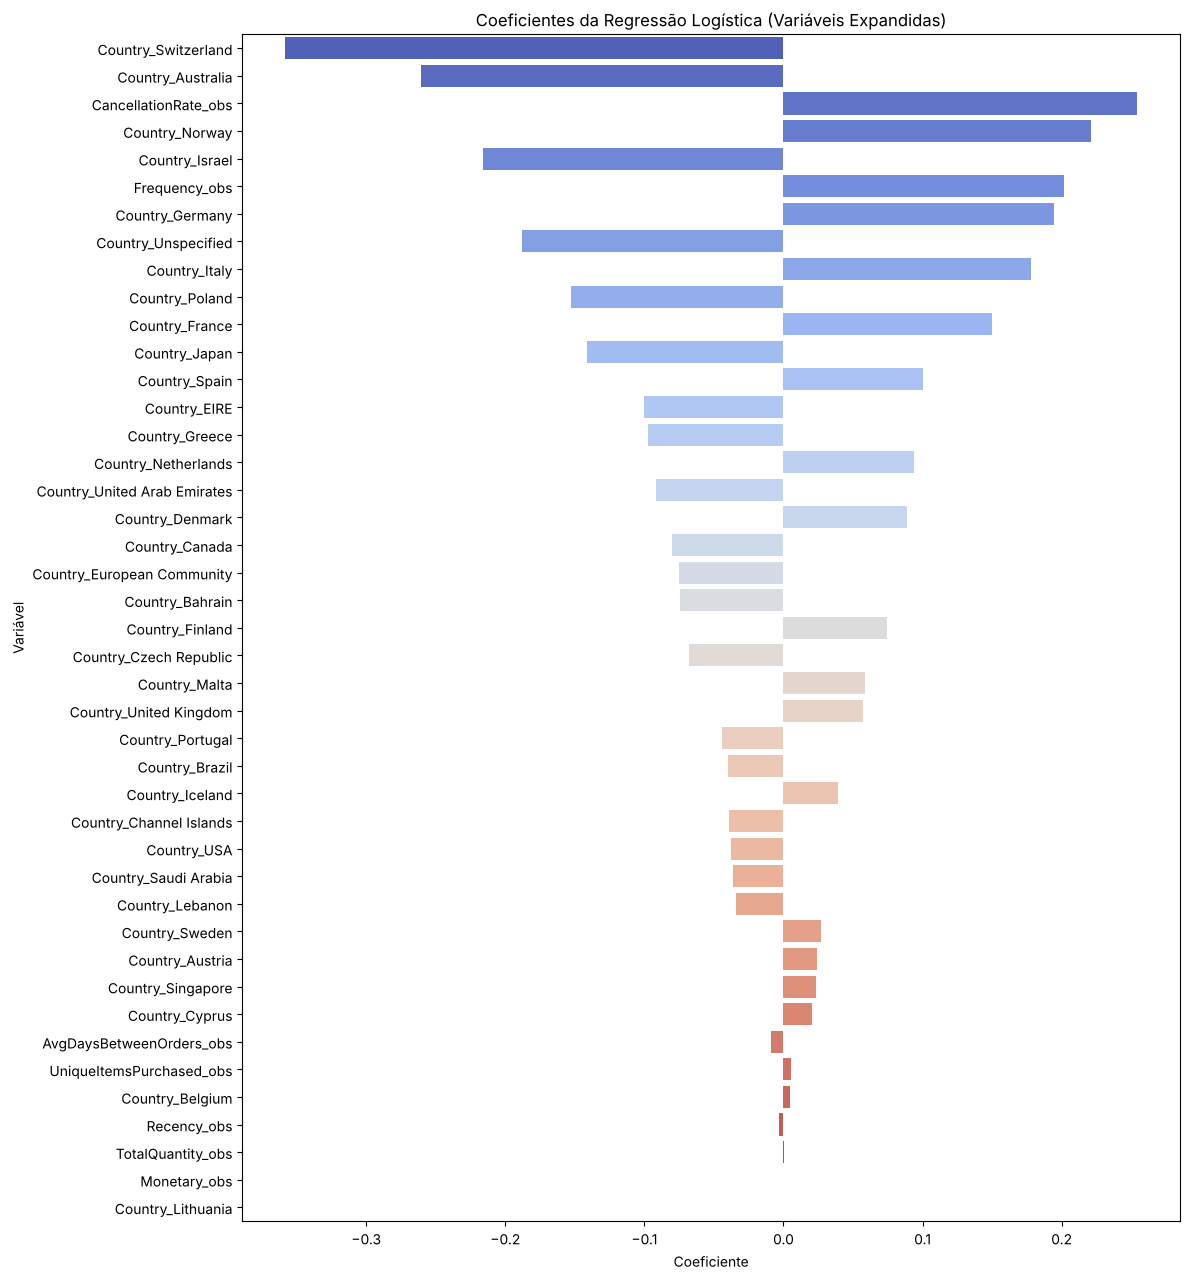

Variáveis selecionadas (14): ['CancellationRate_obs', 'Country_Norway', 'Frequency_obs', 'Country_Germany', 'Country_Italy', 'Country_France', 'Country_Spain', 'Country_EIRE', 'Country_Japan', 'Country_Poland', 'Country_Unspecified', 'Country_Israel', 'Country_Australia', 'Country_Switzerland']
Relatório de Classificação (Regressão Logística - Variáveis Selecionadas):
              precision    recall  f1-score   support

           0       0.63      0.82      0.71       380
           1       0.71      0.48      0.57       351

    accuracy                           0.66       731
   macro avg       0.67      0.65      0.64       731
weighted avg       0.67      0.66      0.65       731

Acurácia: 0.6580
Precisão (Classe 1): 0.7149
Recall (Classe 1): 0.4786
F1-Score (Classe 1): 0.5734
ROC AUC Score: 0.7173


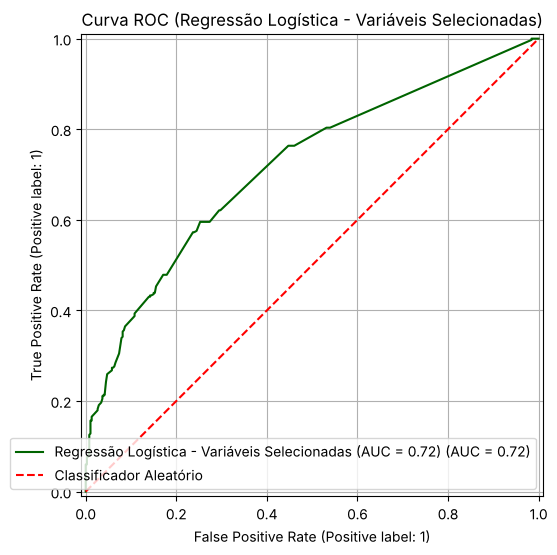

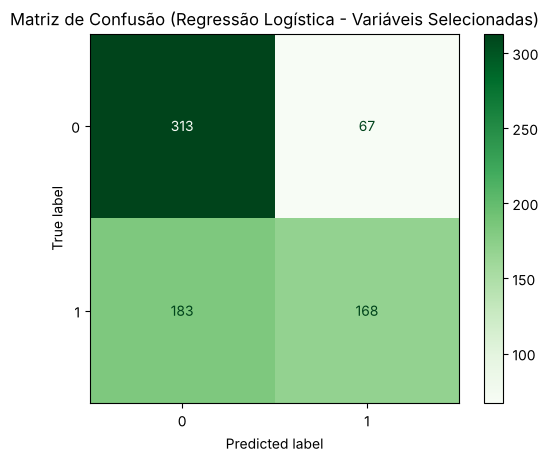

In [35]:
coeficientes_expandidos = importancia_das_variaveis(logistica_expandida, X_expandido.columns,
                                                    'Coeficientes da Regressão Logística (Variáveis Expandidas)', paleta='coolwarm')
mais_impactantes = coeficientes_expandidos[coeficientes_expandidos['Coeficiente'].abs() > LIMIAR_DO_COEFICIENTE]
variaveis_selecionadas = mais_impactantes.sort_values(by='Coeficiente', ascending=False)['Variável'].tolist()
print(f"Variáveis selecionadas ({len(variaveis_selecionadas)}): {variaveis_selecionadas}")

divisao_selecionada = dividir_treino_e_teste(X_expandido[variaveis_selecionadas], base_expandida['Repurchase_60_Days'])
resultados['Logística (Selecionadas)'] = treinar_e_avaliar(regressao_logistica(), 'Regressão Logística - Variáveis Selecionadas',
                                                          divisao_selecionada, cor='darkgreen', mapa_de_cores=plt.cm.Greens)

## Etapa 3 de testes: variáveis agregadas

Cinco variáveis por cliente: recência, frequência, valor monetário, quantidade total de itens e diversidade de produtos.

In [36]:
ultima_data_observada = observacao['InvoiceDate'].max()
variaveis_agregadas = observacao.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda datas: (ultima_data_observada - datas.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    UniqueItems=('StockCode', 'nunique'),
).reset_index().rename(columns={'CustomerID': 'ID'})

divisao_agregada = dividir_treino_e_teste(variaveis_agregadas.drop(columns=['ID']), alvo['Repurchase_60_Days'])
display(variaveis_agregadas.head())

,ID,Recency,Frequency,Monetary,TotalQuantity,UniqueItems
0,12347.0,69,5,2541.26,1350,81
1,12348.0,188,3,200.60,236,8
2,12350.0,249,1,294.40,196,16
3,12352.0,11,6,1154.01,401,45
4,12353.0,143,1,89.00,20,4


Relatório de Classificação (Logística (Agregada)):
              precision    recall  f1-score   support

           0       0.55      0.42      0.47       380
           1       0.50      0.63      0.56       351

    accuracy                           0.52       731
   macro avg       0.53      0.52      0.52       731
weighted avg       0.53      0.52      0.51       731

Acurácia: 0.5198
Precisão (Classe 1): 0.5000
Recall (Classe 1): 0.6325
F1-Score (Classe 1): 0.5585
ROC AUC Score: 0.5274


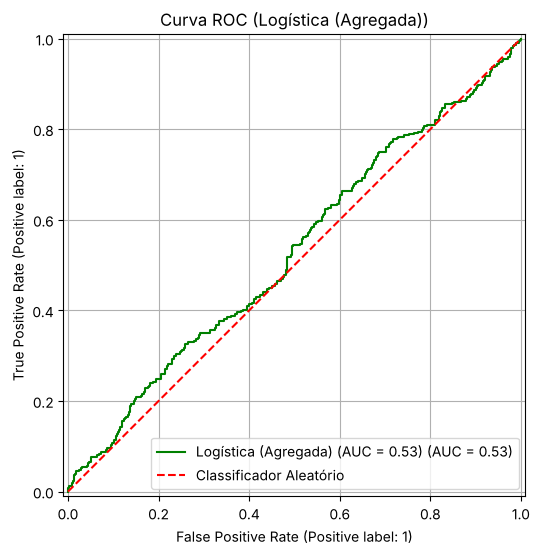

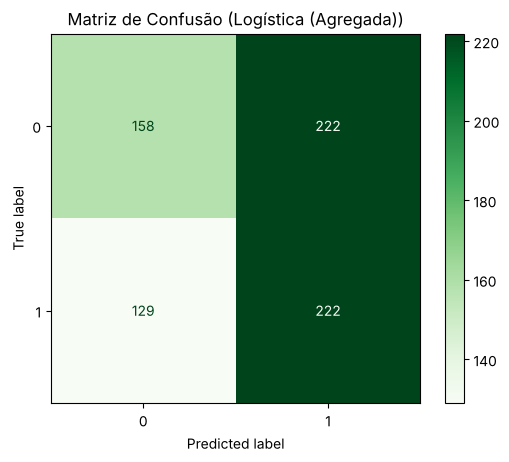

Relatório de Classificação (Árvore de Decisão (Agregada)):
              precision    recall  f1-score   support

           0       0.53      0.53      0.53       380
           1       0.49      0.49      0.49       351

    accuracy                           0.51       731
   macro avg       0.51      0.51      0.51       731
weighted avg       0.51      0.51      0.51       731

Acurácia: 0.5130
Precisão (Classe 1): 0.4928
Recall (Classe 1): 0.4900
F1-Score (Classe 1): 0.4914
ROC AUC Score: 0.5121


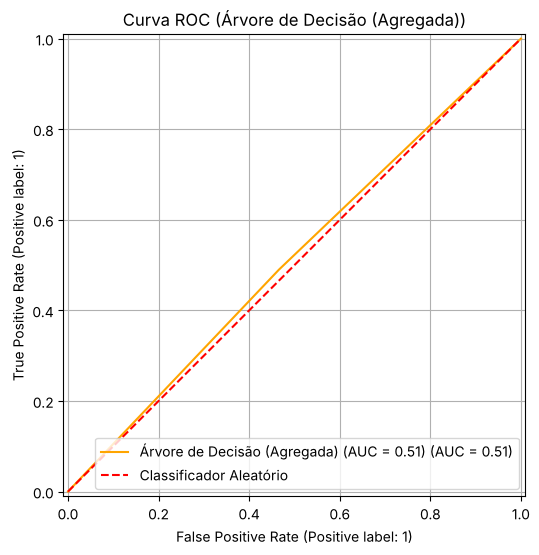

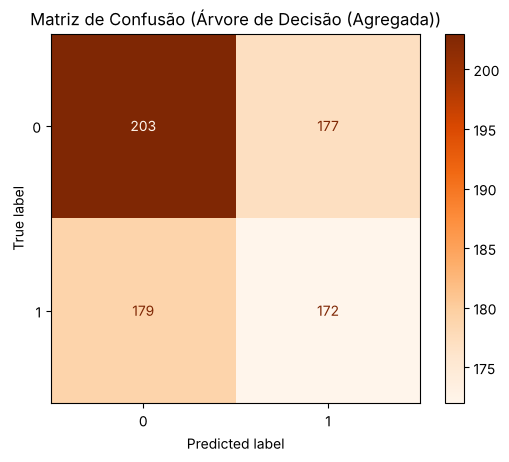

Relatório de Classificação (Random Forest (Agregada)):
              precision    recall  f1-score   support

           0       0.51      0.57      0.54       380
           1       0.47      0.41      0.44       351

    accuracy                           0.49       731
   macro avg       0.49      0.49      0.49       731
weighted avg       0.49      0.49      0.49       731

Acurácia: 0.4925
Precisão (Classe 1): 0.4673
Recall (Classe 1): 0.4074
F1-Score (Classe 1): 0.4353
ROC AUC Score: 0.4712


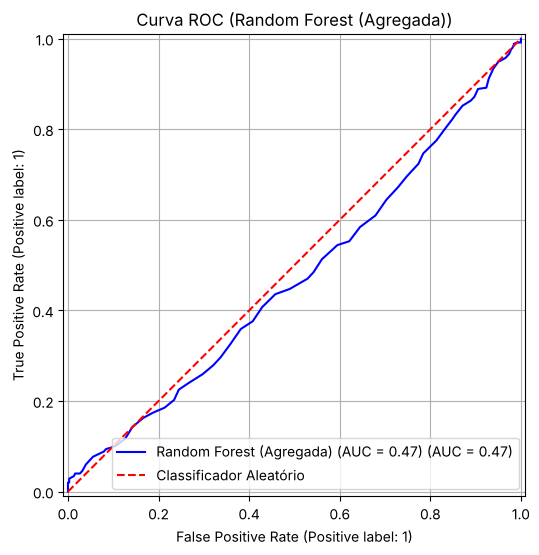

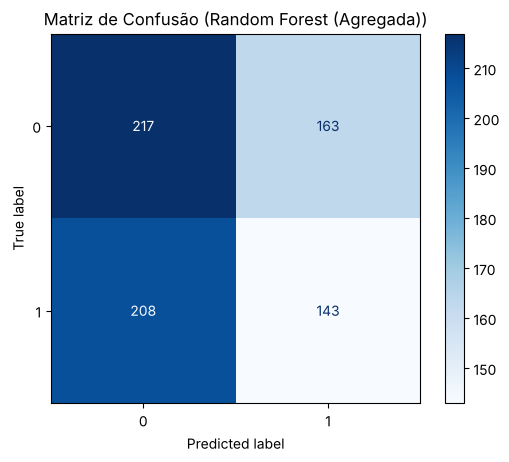

Relatório de Classificação (LightGBM (Agregada)):
              precision    recall  f1-score   support

           0       0.51      0.51      0.51       380
           1       0.47      0.47      0.47       351

    accuracy                           0.49       731
   macro avg       0.49      0.49      0.49       731
weighted avg       0.49      0.49      0.49       731

Acurácia: 0.4897
Precisão (Classe 1): 0.4688
Recall (Classe 1): 0.4701
F1-Score (Classe 1): 0.4694
ROC AUC Score: 0.4780


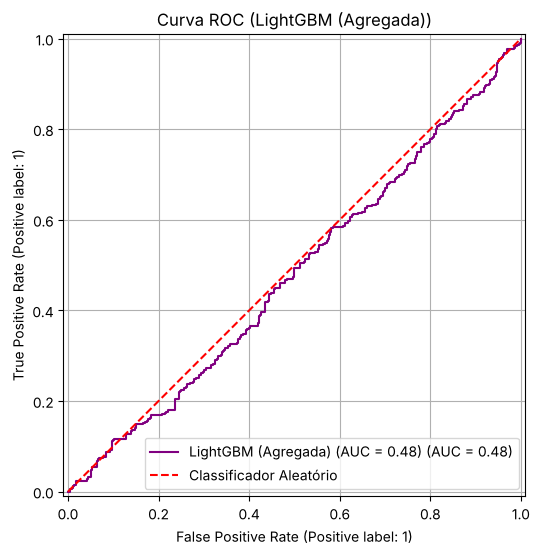

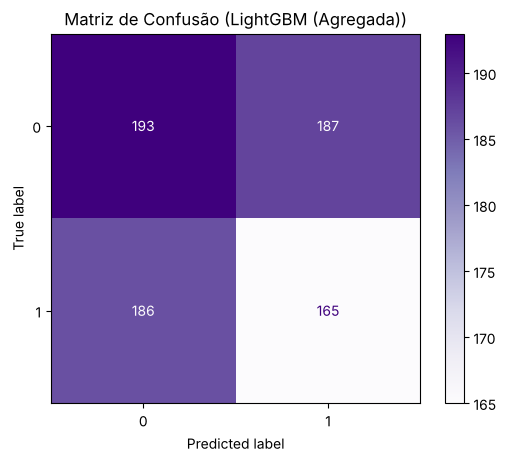

Relatório de Classificação (XGBoost (Agregada)):
              precision    recall  f1-score   support

           0       0.51      0.53      0.52       380
           1       0.47      0.45      0.46       351

    accuracy                           0.49       731
   macro avg       0.49      0.49      0.49       731
weighted avg       0.49      0.49      0.49       731

Acurácia: 0.4897
Precisão (Classe 1): 0.4673
Recall (Classe 1): 0.4473
F1-Score (Classe 1): 0.4571
ROC AUC Score: 0.4824


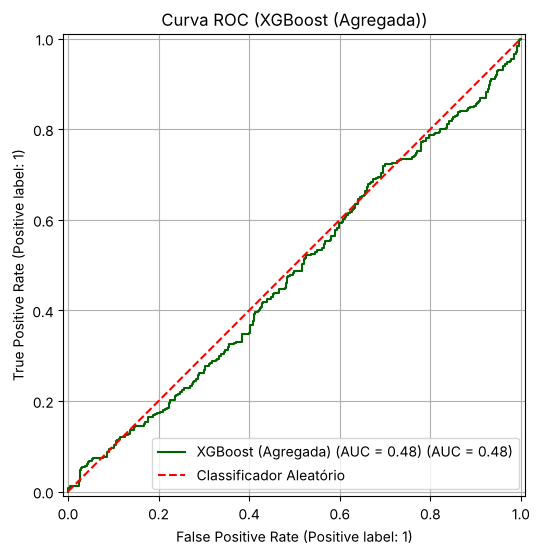

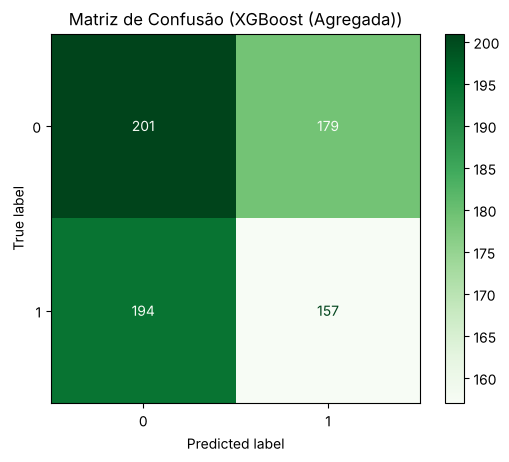

Métrica,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1),ROC AUC Score
Logística (Agregada),0.5198,0.5000,0.6325,0.5585,0.5274
Árvore de Decisão (Agregada),0.5130,0.4928,0.4900,0.4914,0.5121
Random Forest (Agregada),0.4925,0.4673,0.4074,0.4353,0.4712
LightGBM (Agregada),0.4897,0.4688,0.4701,0.4694,0.4780
XGBoost (Agregada),0.4897,0.4673,0.4473,0.4571,0.4824


O melhor modelo com base no F1-Score da classe 1 é: Logística (Agregada) com F1-Score: 0.5585


In [37]:
y_treino_agregado = divisao_agregada[2]
modelos_agregados = [
    ('Logística (Agregada)', regressao_logistica(), 'green', plt.cm.Greens),
    ('Árvore de Decisão (Agregada)', arvore_de_decisao(), 'orange', plt.cm.Oranges),
    ('Random Forest (Agregada)', floresta_aleatoria(), 'blue', plt.cm.Blues),
    ('LightGBM (Agregada)', lightgbm(), 'purple', plt.cm.Purples),
    ('XGBoost (Agregada)', xgboost_balanceado(y_treino_agregado), 'darkgreen', plt.cm.Greens),
]
for nome, modelo, cor, mapa in modelos_agregados:
    resultados[nome] = treinar_e_avaliar(modelo, nome, divisao_agregada, cor=cor, mapa_de_cores=mapa)

comparar_modelos({nome: resultados[nome] for nome, *_ in modelos_agregados});

# Conclusões

### Comparativo final de todos os modelos

In [38]:
comparativo_final = comparar_modelos(resultados)

Métrica,Acurácia,Precisão (Classe 1),Recall (Classe 1),F1-Score (Classe 1),ROC AUC Score
Logística (RFM),0.6676,0.6929,0.5527,0.6149,0.7267
Random Forest (RFM),0.6197,0.6159,0.5527,0.5826,0.6782
Logística (Expandida),0.6703,0.6978,0.5527,0.6169,0.7308
Random Forest (Expandida),0.6539,0.6655,0.5613,0.6090,0.7041
Árvore de Decisão (Expandida),0.5677,0.5519,0.5299,0.5407,0.5663
LightGBM (Expandida),0.6361,0.6412,0.5499,0.5920,0.6935
Logística (Selecionadas),0.6580,0.7149,0.4786,0.5734,0.7173
Logística (Agregada),0.5198,0.5000,0.6325,0.5585,0.5274
Árvore de Decisão (Agregada),0.5130,0.4928,0.4900,0.4914,0.5121
Random Forest (Agregada),0.4925,0.4673,0.4074,0.4353,0.4712


O melhor modelo com base no F1-Score da classe 1 é: Logística (Expandida) com F1-Score: 0.6169


### Sugestão de Itens para os 50 Clientes Mais Importantes

In [39]:
# Ganho estimado = valor gasto na observação × probabilidade de recompra (Regressão Logística - RFM)
clientes_priorizados['Ganho Estimado 60 Dias'] = clientes_priorizados['Monetary_obs'] * clientes_priorizados['Probabilidade']
clientes_mais_importantes = clientes_priorizados.nlargest(TOP_CLIENTES_PRIORITARIOS, 'Ganho Estimado 60 Dias')
print(f"Top {TOP_CLIENTES_PRIORITARIOS} clientes mais importantes e estimativa de ganho (próximos 60 dias):")
display(clientes_mais_importantes[['ID', 'Monetary_obs', 'Probabilidade', 'Ganho Estimado 60 Dias']])

compras_dos_mais_importantes = vendas[vendas['CustomerID'].isin(clientes_mais_importantes['ID'])]
itens_dos_mais_importantes = top_itens(compras_dos_mais_importantes.groupby('Description')['Quantity'].sum().sort_values(ascending=False), 10, 'Quantidade')
print(f"Top 10 itens mais comprados pelos {TOP_CLIENTES_PRIORITARIOS} clientes mais importantes:")
display(itens_dos_mais_importantes)

Top 50 clientes mais importantes e estimativa de ganho (próximos 60 dias):


,ID,Monetary_obs,Probabilidade,Ganho Estimado 60 Dias
62,14911.0,78552.24,1.000000,78552.240000
822,14646.0,44237.97,1.000000,44237.969991
225,13089.0,40195.24,1.000000,40195.240000
192,14156.0,36795.89,1.000000,36795.889808
672,14298.0,34226.85,1.000000,34226.849583
14,17511.0,28270.36,0.999999,28270.317943
66,17841.0,25476.99,1.000000,25476.990000
885,12415.0,23622.53,0.999935,23620.988098
1107,14088.0,21079.83,0.999472,21068.708889
7,15311.0,20656.71,1.000000,20656.709984


Top 10 itens mais comprados pelos 50 clientes mais importantes:


,Descrição,Quantidade
0,WHITE HANGING HEART T-LIGHT HOLDER,3528
1,REGENCY CAKESTAND 3 TIER,3128
2,ASSORTED COLOUR BIRD ORNAMENT,2607
3,PACK OF 72 RETROSPOT CAKE CASES,2041
4,ROSES REGENCY TEACUP AND SAUCER,2017
5,LUNCH BAG RED RETROSPOT,1973
6,PARTY BUNTING,1919
7,PAPER BUNTING RETROSPOT,1860
8,CHILLI LIGHTS,1757
9,CLOTHES PEGS RETROSPOT PACK 24,1663


Com base nesta análise, sugiro considerar a promoção ou oferta desses 10 itens que são frequentemente comprados pelos seus clientes mais valiosos. Isso pode incluir ofertas personalizadas, lançamentos de novos produtos relacionados, ou pacotes especiais com esses itens.

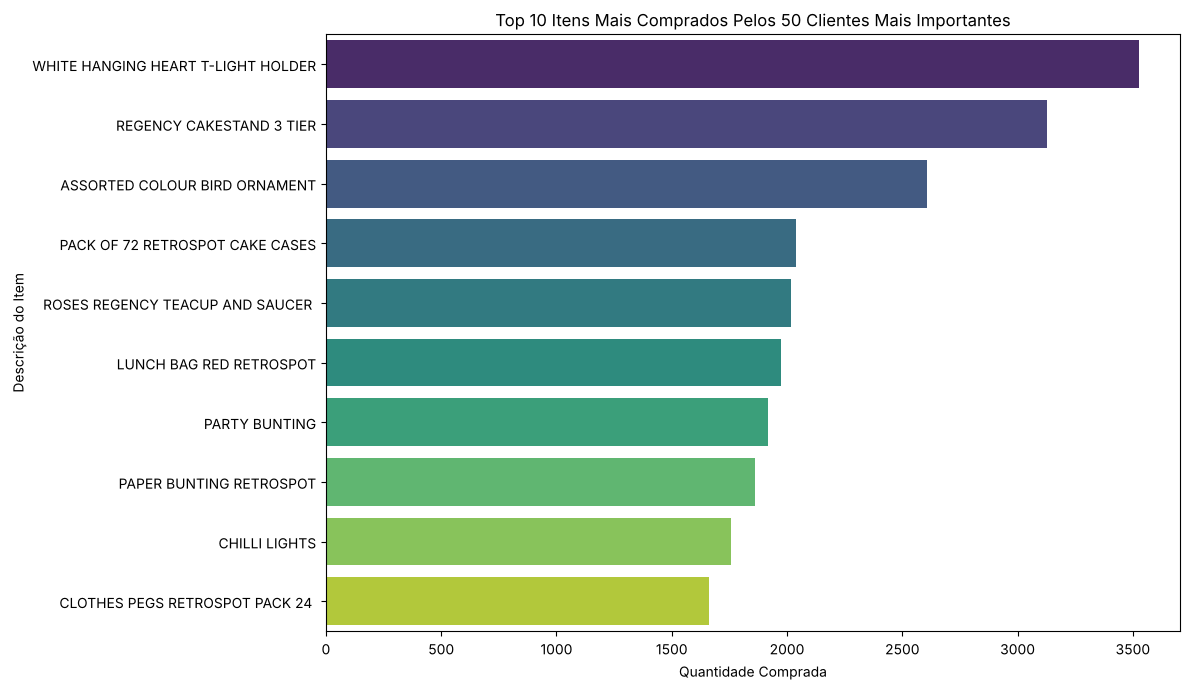

In [40]:
grafico_de_barras(itens_dos_mais_importantes, x='Quantidade', y='Descrição',
                  titulo=f'Top 10 Itens Mais Comprados Pelos {TOP_CLIENTES_PRIORITARIOS} Clientes Mais Importantes',
                  rotulo_x='Quantidade Comprada', rotulo_y='Descrição do Item')

### Sugestões de uso

- Utilização para ver quais itens são mais comprados por quais clientes (criação de lista de emails com promoções personalizadas)
- Priorização de clientes para lista de emails/mensagens
- Controle de compra de futuros itens (pois foram identificados itens que praticamente nunca são vendidos)
- Priorização de produtos por país

### Decisões metodológicas

- Exclusão dos cancelados do dataset
- Exclusão dos clientes sem id
- Treinamento de diversos modelos com uso de IA para decisão de features selecionadas
- Exclusão da geolocalização das features selecionadas devido a desbalanceamento dos dados